# Colombo Monsoon Dry Spell Simulator

## Research Question and Objectives

How does the probability of consecutive dry days vary across Colombo's monsoon seasons?

This project estimates seasonal wet and dry rainfall transitions using historical daily rainfall data from 1991–2018, applies Monte Carlo simulation to estimate dry spell risk, and evaluates the model using held-out data from 2019–2025.

The model simulates rainfall occurrence rather than rainfall intensity.

## Reproduction Instructions

Run all cells from top to bottom in Google Colab or a local Jupyter environment. The notebook automatically checks for the required historical rainfall dataset and downloads it if it is unavailable locally.

Generated datasets, trained model parameters and simulation results are saved in the corresponding project directories.

The simulation uses fixed random seeds to support reproducibility.


In [1]:
import time
NOTEBOOK_START = time.perf_counter()
%pip install -q pandas numpy matplotlib seaborn scikit-learn scipy
import sys, platform, importlib.metadata as md
from pathlib import Path
print(sys.version, platform.platform())
for package in ['pandas','numpy','matplotlib','seaborn','scikit-learn','scipy']:
    print(package, md.version(package))


Note: you may need to restart the kernel to use updated packages.
3.14.3 (tags/v3.14.3:323c59a, Feb  3 2026, 16:04:56) [MSC v.1944 64 bit (AMD64)] Windows-11-10.0.26300-SP0
pandas 3.1.1
numpy 2.5.5
matplotlib 3.11.2
seaborn 0.13.2
scikit-learn 1.9.1
scipy 1.18.1


# 01 - Data Exploration (Implementation)

## Objective

The objective of this notebook is to load, inspect
and understand the historical daily rainfall dataset
for Colombo from 1991 to 2025.

The original CSV file contains geographical and
timezone metadata. These rows are skipped during
data loading to extract the daily rainfall records.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from urllib.request import urlretrieve
import hashlib

filename = "colombo_daily_rainfall_1991_2025.csv"

DATA_URL = (
    "https://raw.githubusercontent.com/"
    "NikiniBandara/colombo-monsoon-dry-spell-simulator/"
    "main/data/colombo_daily_rainfall_1991_2025.csv"
)

ROOT = (
    Path.cwd().parent
    if (Path.cwd().parent / "data" / filename).exists()
    else Path.cwd()
)

DATA = ROOT / "data"
MODELS = ROOT / "models"
RESULTS = ROOT / "results"

for folder in (DATA, MODELS, RESULTS):
    folder.mkdir(parents=True, exist_ok=True)

source = DATA / filename

if not source.exists():
    print("Downloading historical rainfall dataset...")
    urlretrieve(DATA_URL, source)

print("Dataset:", source.relative_to(ROOT))
print("SHA256:", hashlib.sha256(source.read_bytes()).hexdigest())

with source.open(encoding="utf-8-sig") as f:
    header = next(
        (
            i for i, line in enumerate(f)
            if line.startswith("time,")
            and "precipitation_sum" in line
        ),
        None
    )

if header is None:
    raise ValueError("Expected time and precipitation_sum columns")

df = pd.read_csv(source, skiprows=header)

display(df.head())


Dataset: data\colombo_daily_rainfall_1991_2025.csv
SHA256: 2ae4aef542208ae8e60dca468b53423d536b1800d0a766cc6b90f09a022596e3


,time,precipitation_sum (mm)
0,1991-01-01,9.6
1,1991-01-02,6.9
2,1991-01-03,1.5
3,1991-01-04,0.9
4,1991-01-05,0.3


In [4]:
df = df.rename(columns={
    "time": "date",
    "precipitation_sum (mm)": "rainfall_mm"
})

df.head()

,date,rainfall_mm
0,1991-01-01,9.6
1,1991-01-02,6.9
2,1991-01-03,1.5
3,1991-01-04,0.9
4,1991-01-05,0.3


In [5]:
df["date"] = pd.to_datetime(df["date"])

df["rainfall_mm"] = pd.to_numeric(
    df["rainfall_mm"], errors="coerce"
)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12784 entries, 0 to 12783
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         12784 non-null  datetime64[us]
 1   rainfall_mm  12784 non-null  float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 199.9 KB


In [6]:
df.shape

(12784, 2)

In [7]:
df.isnull().sum()

date           0
rainfall_mm    0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.describe()

,date,rainfall_mm
count,12784,12784.000000
mean,2008-07-01 12:00:00,7.088392
min,1991-01-01 00:00:00,0.000000
25%,1999-10-01 18:00:00,0.900000
50%,2008-07-01 12:00:00,3.600000
75%,2017-04-01 06:00:00,9.400000
max,2025-12-31 00:00:00,231.400000
std,NaN,10.561965


In [10]:
print("Start date:", df["date"].min())
print("End date:", df["date"].max())

Start date: 1991-01-01 00:00:00
End date: 2025-12-31 00:00:00


# 02 - Data Cleaning

In [11]:
print(df.isnull().sum())

date           0
rainfall_mm    0
dtype: int64


In [12]:
print("Duplicate dates:", df["date"].duplicated().sum())

Duplicate dates: 0


In [13]:
df = df.sort_values("date").reset_index(drop=True)

df.head()

,date,rainfall_mm
0,1991-01-01,9.6
1,1991-01-02,6.9
2,1991-01-03,1.5
3,1991-01-04,0.9
4,1991-01-05,0.3


In [14]:
invalid_rainfall = df[df["rainfall_mm"] < 0]

print("Invalid rainfall records:", len(invalid_rainfall))

Invalid rainfall records: 0


In [15]:
expected_dates = pd.date_range(
    start=df["date"].min(),
    end=df["date"].max(),
    freq="D"
)

missing_dates = expected_dates.difference(df["date"])

print("Missing dates:", len(missing_dates))
print(missing_dates)
assert df['date'].notna().all() and df['rainfall_mm'].notna().all(), 'Missing values'
assert np.isfinite(df['rainfall_mm']).all() and (df['rainfall_mm'] >= 0).all(), 'Invalid rainfall'
assert not df['date'].duplicated().any(), 'Duplicate dates'
assert df['date'].equals(pd.Series(pd.date_range('1991-01-01','2025-12-31'))), 'Unexpected date coverage or gaps' 

Missing dates: 0
DatetimeIndex([], dtype='datetime64[us]', freq='D')


In [16]:
df.to_csv(
    DATA / "colombo_rainfall_cleaned.csv",
    index=False
)

# 03 - Exploratory Data Analysis (EDA)

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    DATA / "colombo_rainfall_cleaned.csv",
    parse_dates=["date"]
)

df.head()

,date,rainfall_mm
0,1991-01-01,9.6
1,1991-01-02,6.9
2,1991-01-03,1.5
3,1991-01-04,0.9
4,1991-01-05,0.3


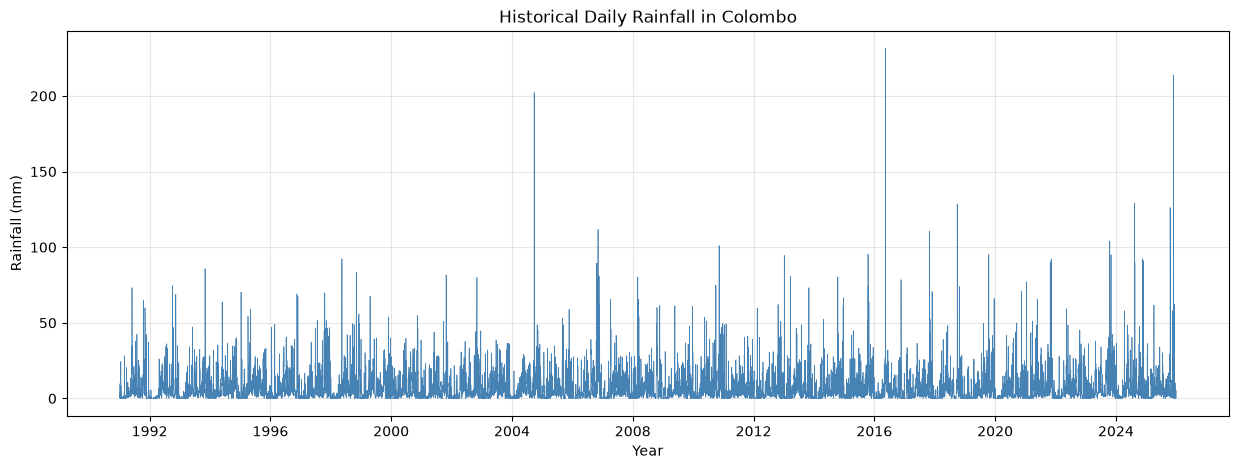

In [18]:
plt.figure(figsize=(15, 5))

plt.plot(df["date"], df["rainfall_mm"],
         color="steelblue", linewidth=0.5)

plt.title("Historical Daily Rainfall in Colombo")
plt.xlabel("Year")
plt.ylabel("Rainfall (mm)")
plt.grid(alpha=0.3)
plt.show()

Daily rainfall is usually low, with occasional sharp peaks. The highest recorded day is 15 May 2016 at 231.4 mm.

In [19]:
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month

In [20]:
monthly_totals = df.groupby(
    ["year", "month"]
)["rainfall_mm"].sum()

monthly_average = monthly_totals.groupby(
    "month"
).mean()

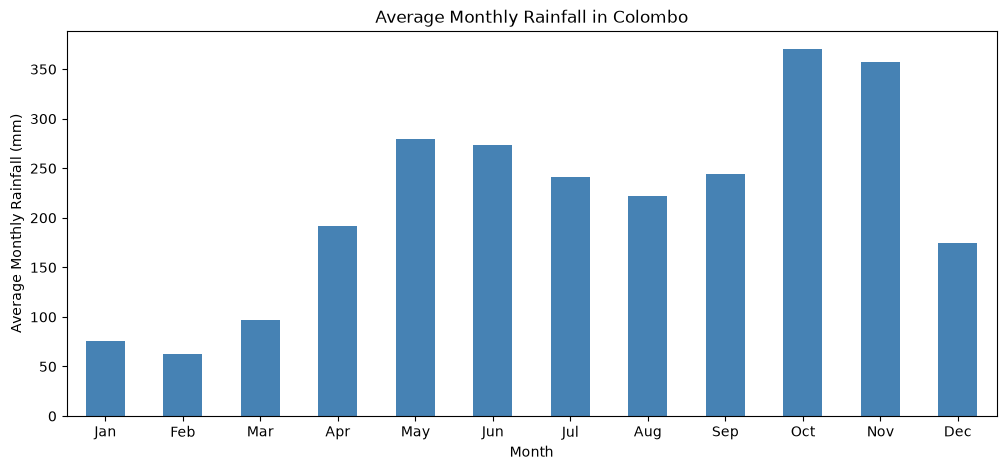

In [21]:
plt.figure(figsize=(12, 5))

monthly_average.plot(
    kind="bar",
    color="steelblue"
)

plt.title("Average Monthly Rainfall in Colombo")
plt.xlabel("Month")
plt.ylabel("Average Monthly Rainfall (mm)")

plt.xticks(
    ticks=range(12),
    labels=["Jan", "Feb", "Mar", "Apr",
            "May", "Jun", "Jul", "Aug",
            "Sep", "Oct", "Nov", "Dec"],
    rotation=0
)

plt.show()

October has the highest average monthly rainfall (369.98 mm), followed by November (357.54 mm). February is lowest (62.15 mm).

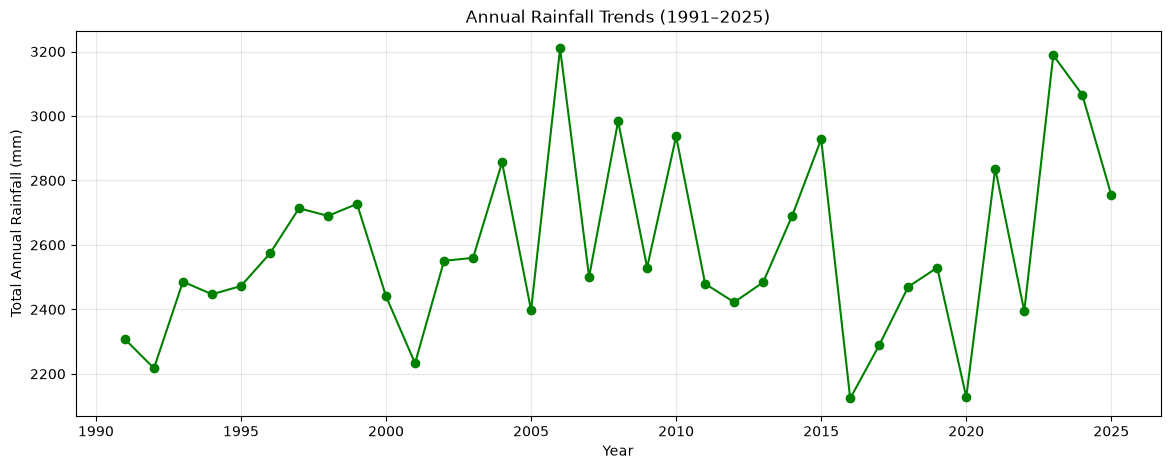

In [22]:
annual_rainfall = df.groupby("year")[
    "rainfall_mm"
].sum()

plt.figure(figsize=(14, 5))

annual_rainfall.plot(
    kind="line",
    marker="o",
    color="green"
)

plt.title("Annual Rainfall Trends (1991–2025)")
plt.xlabel("Year")
plt.ylabel("Total Annual Rainfall (mm)")
plt.grid(alpha=0.3)
plt.show()

Annual rainfall varies across the years. 2006 is highest (3,209.6 mm), and 2016 is lowest (2,123.7 mm).

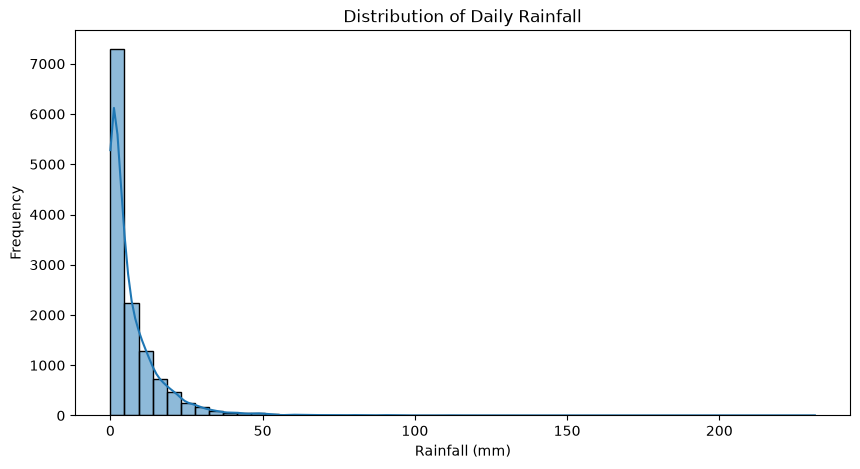

In [23]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="rainfall_mm",
    bins=50,
    kde=True
)

plt.title("Distribution of Daily Rainfall")
plt.xlabel("Rainfall (mm)")
plt.ylabel("Frequency")
plt.show()

Most days have low rainfall, while a smaller number have high amounts. The distribution has a long right tail reaching 231.4 mm.

In [24]:
rainy_days = (df["rainfall_mm"] > 0).sum()
dry_days = (df["rainfall_mm"] == 0).sum()

print("Days with rainfall:", rainy_days)
print("Zero-rainfall days:", dry_days)


Days with rainfall: 10920
Zero-rainfall days: 1864


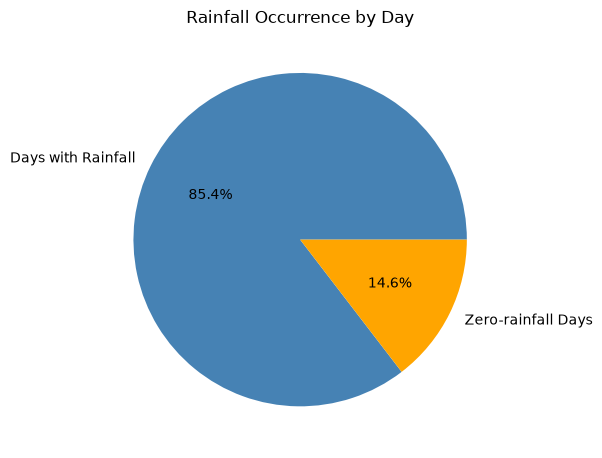

In [25]:
plt.figure(figsize=(6, 6))

plt.pie(
    [rainy_days, dry_days],
    labels=["Days with Rainfall", "Zero-rainfall Days"],
    autopct="%1.1f%%",
    colors=["steelblue", "orange"]
)

plt.title("Rainfall Occurrence by Day")
plt.tight_layout()
plt.show()


There are 10,920 rainy days (85.4%) and 1,864 zero-rainfall days (14.6%). Here, rainy means rainfall above 0 mm.

In [26]:
df.nlargest(10, "rainfall_mm")[
    ["date", "rainfall_mm"]
]

,date,rainfall_mm
9266,2016-05-15,231.4
12750,2025-11-28,213.9
5017,2004-09-26,202.2
12278,2024-08-13,129.2
10134,2018-09-30,128.6
12709,2025-10-18,126.2
12749,2025-11-27,117.0
5789,2006-11-07,111.7
9800,2017-10-31,110.7
11978,2023-10-18,104.1


The highest daily rainfall is 231.4 mm on 15 May 2016. The next highest are 213.9 mm on 28 November 2025 and 202.2 mm on 26 September 2004. These records remain in the data.

# 04 - Feature Engineering and Dry Spell Identification

## Objective

The objective of this section is to identify wet and
dry days, classify rainfall records into monsoon seasons,
calculate consecutive dry days and prepare the dataset
for dry spell simulation.

In [27]:
DRY_THRESHOLD = 1.0

df["is_dry"] = (
    df["rainfall_mm"] < DRY_THRESHOLD
).astype(int)

df["is_wet"] = 1 - df["is_dry"]

df.head(10)

,date,rainfall_mm,year,month,is_dry,is_wet
0,1991-01-01,9.6,1991,1,0,1
1,1991-01-02,6.9,1991,1,0,1
2,1991-01-03,1.5,1991,1,0,1
3,1991-01-04,0.9,1991,1,1,0
4,1991-01-05,0.3,1991,1,1,0
5,1991-01-06,2.4,1991,1,0,1
6,1991-01-07,1.4,1991,1,0,1
7,1991-01-08,0.1,1991,1,1,0
8,1991-01-09,0.0,1991,1,1,0
9,1991-01-10,4.6,1991,1,0,1


In [28]:
print("Dry days:", df["is_dry"].sum())
print("Wet days:", df["is_wet"].sum())
print("Dry day probability:", df["is_dry"].mean())

Dry days: 3301
Wet days: 9483
Dry day probability: 0.2582133917396746


The previous exploratory data analysis identified
days with exactly zero rainfall.

For dry spell simulation, a threshold of 1 mm is used.
A day receiving less than 1 mm of rainfall is classified
as a dry day, while a day receiving 1 mm or more is
classified as a wet day.

In [29]:
def get_season(month):
    if month in [12, 1, 2]:
        return "Northeast Monsoon"
    elif month in [3, 4]:
        return "First Inter-monsoon"
    elif month in [5, 6, 7, 8, 9]:
        return "Southwest Monsoon"
    else:
        return "Second Inter-monsoon"

In [30]:
df["season"] = df["month"].apply(get_season)

df[["date", "rainfall_mm", "season"]].head(10)

,date,rainfall_mm,season
0,1991-01-01,9.6,Northeast Monsoon
1,1991-01-02,6.9,Northeast Monsoon
2,1991-01-03,1.5,Northeast Monsoon
3,1991-01-04,0.9,Northeast Monsoon
4,1991-01-05,0.3,Northeast Monsoon
5,1991-01-06,2.4,Northeast Monsoon
6,1991-01-07,1.4,Northeast Monsoon
7,1991-01-08,0.1,Northeast Monsoon
8,1991-01-09,0.0,Northeast Monsoon
9,1991-01-10,4.6,Northeast Monsoon


In [31]:
df["season"].value_counts()

season
Southwest Monsoon       5355
Northeast Monsoon       3159
First Inter-monsoon     2135
Second Inter-monsoon    2135
Name: count, dtype: int64

In [32]:
df["day"] = df["date"].dt.day
df["day_of_year"] = df["date"].dt.day_of_year

df.head()

,date,rainfall_mm,year,month,is_dry,is_wet,season,day,day_of_year
0,1991-01-01,9.6,1991,1,0,1,Northeast Monsoon,1,1
1,1991-01-02,6.9,1991,1,0,1,Northeast Monsoon,2,2
2,1991-01-03,1.5,1991,1,0,1,Northeast Monsoon,3,3
3,1991-01-04,0.9,1991,1,1,0,Northeast Monsoon,4,4
4,1991-01-05,0.3,1991,1,1,0,Northeast Monsoon,5,5


In [33]:
dry_streak = 0
dry_streaks = []

for is_dry in df["is_dry"]:
    if is_dry == 1:
        dry_streak += 1
    else:
        dry_streak = 0

    dry_streaks.append(dry_streak)

df["consecutive_dry_days"] = dry_streaks

In [34]:
df[[
    "date",
    "rainfall_mm",
    "is_dry",
    "consecutive_dry_days"
]].head(30)

,date,rainfall_mm,is_dry,consecutive_dry_days
0,1991-01-01,9.6,0,0
1,1991-01-02,6.9,0,0
2,1991-01-03,1.5,0,0
3,1991-01-04,0.9,1,1
4,1991-01-05,0.3,1,2
5,1991-01-06,2.4,0,0
6,1991-01-07,1.4,0,0
7,1991-01-08,0.1,1,1
8,1991-01-09,0.0,1,2
9,1991-01-10,4.6,0,0


In [35]:
print(
    "Longest dry spell:",
    df["consecutive_dry_days"].max(),
    "days"
)

Longest dry spell: 31 days


In [36]:
df["spell_id"] = (
    df["is_dry"] != df["is_dry"].shift()
).cumsum()

In [37]:
dry_spells = (
    df[df["is_dry"] == 1]
    .groupby("spell_id")
    .agg(
        start_date=("date", "min"),
        end_date=("date", "max"),
        duration=("date", "size"),
        season=("season", "first")
    )
    .reset_index(drop=True)
)

dry_spells.head(10)

,start_date,end_date,duration,season
0,1991-01-04,1991-01-05,2,Northeast Monsoon
1,1991-01-08,1991-01-09,2,Northeast Monsoon
2,1991-01-12,1991-01-14,3,Northeast Monsoon
3,1991-01-18,1991-01-18,1,Northeast Monsoon
4,1991-01-21,1991-02-01,12,Northeast Monsoon
5,1991-02-04,1991-02-23,20,Northeast Monsoon
6,1991-02-25,1991-02-25,1,Northeast Monsoon
7,1991-03-06,1991-03-06,1,First Inter-monsoon
8,1991-03-08,1991-03-09,2,First Inter-monsoon
9,1991-03-11,1991-03-14,4,First Inter-monsoon


This approach assigns a dry spell to the season in
which it started, even if it continues into another
season.

In [38]:
print("Total dry spells:", len(dry_spells))

print(
    "Average duration:",
    dry_spells["duration"].mean()
)

print(
    "Longest duration:",
    dry_spells["duration"].max()
)

print(
    "Spells lasting at least 7 days:",
    (dry_spells["duration"] >= 7).sum()
)

dry_spells["duration"].describe()

Total dry spells: 939
Average duration: 3.5154419595314166
Longest duration: 31
Spells lasting at least 7 days: 146


count    939.000000
mean       3.515442
std        4.125500
min        1.000000
25%        1.000000
50%        2.000000
75%        4.000000
max       31.000000
Name: duration, dtype: float64

In [39]:
dry_spells.nlargest(10, "duration")

,start_date,end_date,duration,season
29,1992-01-19,1992-02-18,31,Northeast Monsoon
768,2020-01-05,2020-02-01,28,Northeast Monsoon
539,2012-01-11,2012-02-04,25,Northeast Monsoon
53,1992-12-30,1993-01-22,24,Northeast Monsoon
678,2016-12-29,2017-01-20,23,Northeast Monsoon
464,2009-01-29,2009-02-19,22,Northeast Monsoon
601,2014-01-30,2014-02-19,21,Northeast Monsoon
5,1991-02-04,1991-02-23,20,Northeast Monsoon
419,2006-12-21,2007-01-09,20,Northeast Monsoon
421,2007-01-30,2007-02-18,20,Northeast Monsoon


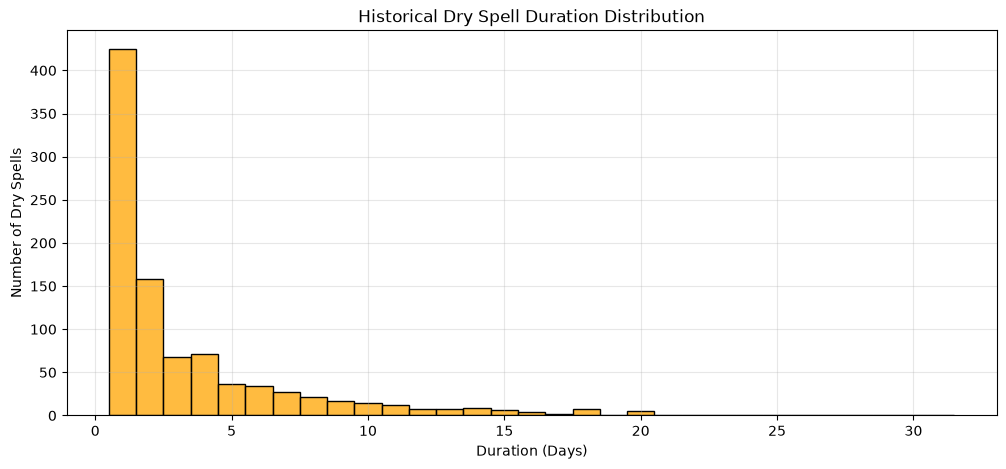

In [40]:
plt.figure(figsize=(12, 5))

sns.histplot(
    dry_spells["duration"],
    discrete=True,
    color="orange"
)

plt.title("Historical Dry Spell Duration Distribution")
plt.xlabel("Duration (Days)")
plt.ylabel("Number of Dry Spells")
plt.grid(alpha=0.3)
plt.show()

In [41]:
seasonal_dry_probability = (
    df.groupby("season")["is_dry"].mean()
)

seasonal_dry_probability

season
First Inter-monsoon     0.333958
Northeast Monsoon       0.626781
Second Inter-monsoon    0.141452
Southwest Monsoon       0.057143
Name: is_dry, dtype: float64

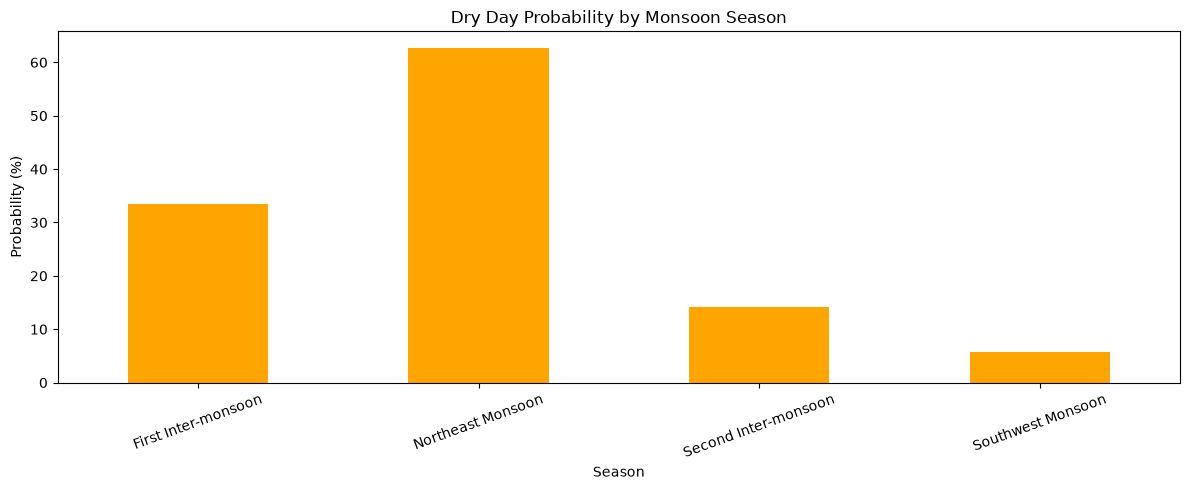

In [42]:
plt.figure(figsize=(12, 5))

(seasonal_dry_probability * 100).plot(
    kind="bar",
    color="orange"
)

plt.title("Dry Day Probability by Monsoon Season")
plt.xlabel("Season")
plt.ylabel("Probability (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [43]:
seasonal_spell_stats = (
    dry_spells.groupby("season")["duration"]
    .agg(["count", "mean", "median", "max"])
)

seasonal_spell_stats

,count,mean,median,max
season,,,,
First Inter-monsoon,244,2.598361,2.0,18
Northeast Monsoon,361,5.614958,4.0,31
Second Inter-monsoon,141,2.375887,1.0,18
Southwest Monsoon,193,1.580311,1.0,8


In [44]:
df.to_csv(
    DATA / "colombo_rainfall_features.csv",
    index=False
)

In [45]:
dry_spells.to_csv(
    DATA / "colombo_dry_spells.csv",
    index=False
)

# 05 - Seasonal Markov Model (Assumptions and Equations)

## Objective

The objective of this section is to develop a
first-order seasonal Markov chain model using
historical daily rainfall data.

The model estimates transition probabilities
between wet and dry days for each monsoon season.

These probabilities will subsequently be used
in Monte Carlo simulations to estimate dry spell
frequency, duration and probability.

## Concepts applied

Historical wet/dry transition counts provide **empirical input modelling**. The season-dependent matrices form a **discrete-time Markov chain** using conditional transition probabilities. Uniform pseudorandom draws are **random variate generation**; repeated paths are **Monte Carlo simulation**. The **law of large numbers** explains why estimates settle as the number of paths grows. **Confidence intervals** describe finite-simulation sampling uncertainty under the fitted model.


## Mathematical formulation
Let $X_t=1$ for rainfall below 1 mm and $X_t=0$ otherwise. With destination-day season $s(t)$, the first-order assumption is $P(X_t=j\mid X_{t-1}=i,\ldots)=P^{s(t)}_{ij}$. Estimate $\hat P^s_{ij}=N^s_{ij}/\sum_{k=0}^1 N^s_{ik}$ using training transitions only. Rows sum to one. Within a fixed season, a dry run has geometric duration with $P(L\ge k)=(P^s_{11})^{k-1}$ and $E[L]=1/(1-P^s_{11})$ when $P^s_{11}<1$. This formula does not directly apply across seasonal boundaries.

In [46]:
train_df = df[df["year"] <= 2018].copy()
test_df = df[df["year"] >= 2019].copy()

print("Training records:", len(train_df))
print("Testing records:", len(test_df))

print("Training period:",
      train_df["date"].min(),
      "to",
      train_df["date"].max())

print("Testing period:",
      test_df["date"].min(),
      "to",
      test_df["date"].max())

Training records: 10227
Testing records: 2557
Training period: 1991-01-01 00:00:00 to 2018-12-31 00:00:00
Testing period: 2019-01-01 00:00:00 to 2025-12-31 00:00:00


In [47]:
train_df = train_df.sort_values("date")

train_df["next_state"] = (
    train_df["is_dry"].shift(-1)
)

train_df["next_season"] = (
    train_df["season"].shift(-1)
)

train_df[[
    "date",
    "season",
    "is_dry",
    "next_state"
]].head(10)

,date,season,is_dry,next_state
0,1991-01-01,Northeast Monsoon,0,0.0
1,1991-01-02,Northeast Monsoon,0,0.0
2,1991-01-03,Northeast Monsoon,0,1.0
3,1991-01-04,Northeast Monsoon,1,1.0
4,1991-01-05,Northeast Monsoon,1,0.0
5,1991-01-06,Northeast Monsoon,0,0.0
6,1991-01-07,Northeast Monsoon,0,1.0
7,1991-01-08,Northeast Monsoon,1,1.0
8,1991-01-09,Northeast Monsoon,1,0.0
9,1991-01-10,Northeast Monsoon,0,0.0


In [48]:
transition_df = train_df.dropna(
    subset=["next_state"]
).copy()

transition_df["next_state"] = (
    transition_df["next_state"].astype(int)
)

In [49]:
transition_counts = pd.crosstab(
    transition_df["is_dry"],
    transition_df["next_state"]
).reindex(
    index=[0, 1],
    columns=[0, 1],
    fill_value=0
)

transition_counts

next_state,0,1
is_dry,,
0,6822,738
1,737,1929


In [50]:
transition_matrix = transition_counts.div(
    transition_counts.sum(axis=1),
    axis=0
)

transition_matrix

next_state,0,1
is_dry,,
0,0.902381,0.097619
1,0.276444,0.723556


In [51]:
def calculate_transition_matrix(data):
    counts = pd.crosstab(
        data["is_dry"],
        data["next_state"]
    ).reindex(
        index=[0, 1],
        columns=[0, 1],
        fill_value=0
    )

    probabilities = counts.div(
        counts.sum(axis=1),
        axis=0
    )

    return probabilities

In [52]:
seasons = [
    "Northeast Monsoon",
    "First Inter-monsoon",
    "Southwest Monsoon",
    "Second Inter-monsoon"
]

In [53]:
seasonal_matrices = {}

for season in seasons:
    season_data = transition_df[
        transition_df["next_season"] == season
    ]

    seasonal_matrices[season] = (
        calculate_transition_matrix(season_data)
    )

In [54]:
for season, matrix in seasonal_matrices.items():
    print(f"\n{season}")
    display(matrix.round(4))


Northeast Monsoon


next_state,0,1
is_dry,,
0,0.6991,0.3009
1,0.1729,0.8271



First Inter-monsoon


next_state,0,1
is_dry,,
0,0.8271,0.1729
1,0.3569,0.6431



Southwest Monsoon


next_state,0,1
is_dry,,
0,0.9629,0.0371
1,0.6281,0.3719



Second Inter-monsoon


next_state,0,1
is_dry,,
0,0.9216,0.0784
1,0.4174,0.5826


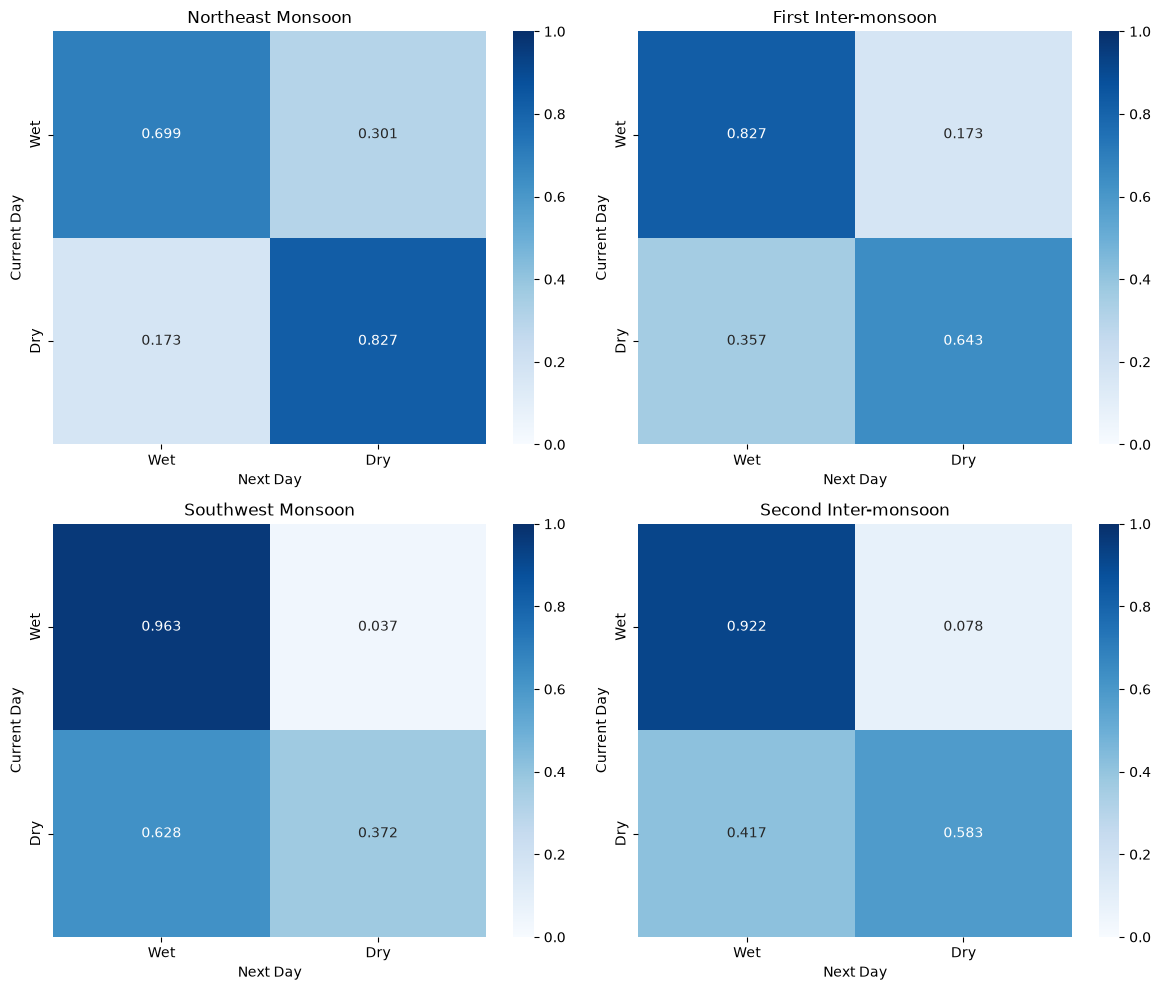

In [55]:
fig, axes = plt.subplots(
    2, 2, figsize=(12, 10)
)

for ax, (season, matrix) in zip(
    axes.flat,
    seasonal_matrices.items()
):
    sns.heatmap(
        matrix,
        annot=True,
        fmt=".3f",
        cmap="Blues",
        vmin=0,
        vmax=1,
        xticklabels=["Wet", "Dry"],
        yticklabels=["Wet", "Dry"],
        ax=ax
    )

    ax.set_title(season)
    ax.set_xlabel("Next Day")
    ax.set_ylabel("Current Day")

plt.tight_layout()
plt.show()

In [56]:
dry_persistence = pd.Series({
    season: matrix.loc[1, 1]
    for season, matrix
    in seasonal_matrices.items()
})

dry_persistence.sort_values(
    ascending=False
)

Northeast Monsoon       0.827091
First Inter-monsoon     0.643103
Second Inter-monsoon    0.582645
Southwest Monsoon       0.371901
dtype: float64

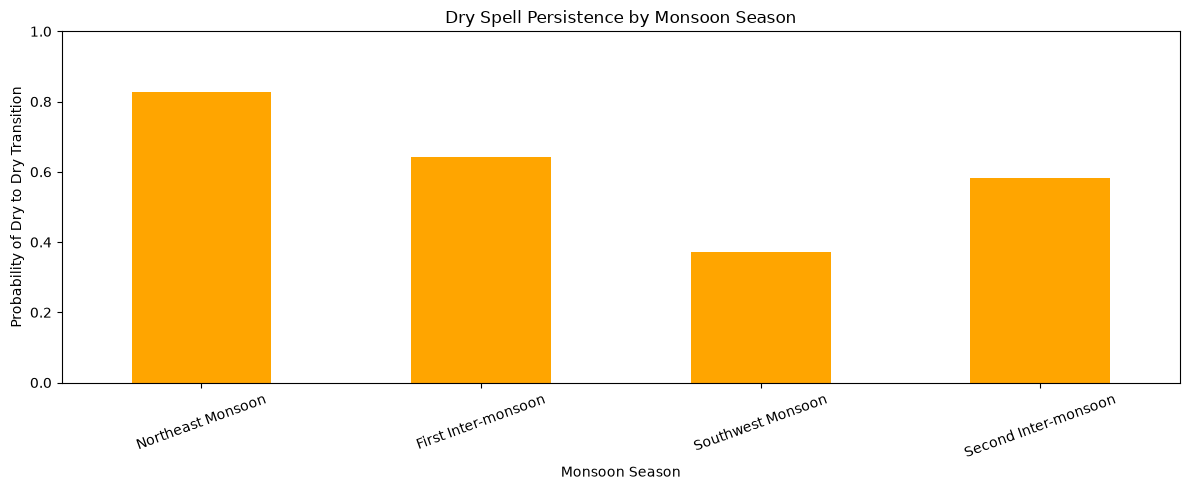

In [57]:
plt.figure(figsize=(12, 5))

dry_persistence.plot(
    kind="bar",
    color="orange"
)

plt.title("Dry Spell Persistence by Monsoon Season")
plt.xlabel("Monsoon Season")
plt.ylabel("Probability of Dry to Dry Transition")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [58]:
for season, matrix in seasonal_matrices.items():
    valid_sum = np.allclose(
        matrix.sum(axis=1),
        1.0
    )

    valid_range = (
        (matrix >= 0) & (matrix <= 1)
    ).all().all()

    print(
        season,
        "- Valid:",
        valid_sum and valid_range
    )
    assert valid_sum and valid_range, f"Invalid matrix: {season}"

Northeast Monsoon - Valid: True
First Inter-monsoon - Valid: True
Southwest Monsoon - Valid: True
Second Inter-monsoon - Valid: True


In [59]:
import json
from pathlib import Path

MODELS.mkdir(exist_ok=True)

In [60]:
model_parameters = {
    "model_type": "First-order seasonal Markov chain",
    "dry_threshold_mm": float(DRY_THRESHOLD),
    "training_start": "1991-01-01",
    "training_end": "2018-12-31",
    "states": ["Wet", "Dry"],
    "seasonal_matrices": {
        season: matrix.to_numpy().tolist()
        for season, matrix
        in seasonal_matrices.items()
    }
}

In [61]:
with open(
    MODELS / "seasonal_markov_model.json",
    "w"
) as file:
    json.dump(
        model_parameters,
        file,
        indent=4
    )

## Observations

- The season with the highest probability of
  dry spell continuation is Northeast Monsoon (0.827091).

- The season with the lowest probability of
  dry spell continuation is Southwest Monsoon (0.371901).

- The transition matrices demonstrate differences
  in seasonal rainfall behaviour.

- All transition probability matrices have been
  mathematically validated.

- The trained model parameters have been saved
  in JSON format for subsequent simulation.

# 06 - Monte Carlo Simulation (Experiments and Results)

## Objective

The objective of this section is to develop a Monte
Carlo simulation using the trained seasonal Markov
chain model.

The simulation generates multiple possible future
wet and dry day sequences to estimate dry spell
probabilities, durations and seasonal risks.

A random seed is used to ensure reproducibility.

## Monte Carlo uncertainty
For independent simulated paths, draw $U_t\sim U(0,1)$ and set $X_t=1$ when $U_t<P^{s(t)}_{X_{t-1},1}$. The initial state is the day before the simulated window. Let $L_r$ be the longest within-window run in path $r$. Then $\hat p_k=N^{-1}\sum_r I(L_r\ge k)$, with estimated standard error $\sqrt{\hat p_k(1-\hat p_k)/N}$. Use the 95% Wilson interval with center $(\hat p+z^2/(2N))/(1+z^2/N)$ and half-width $z\sqrt{\hat p(1-\hat p)/N+z^2/(4N^2)}/(1+z^2/N)$, where $z=1.96$. Mean confidence intervals use $\bar x\pm t_{.975,n-1}s/\sqrt n$. Empirical 2.5th and 97.5th percentiles describe path variability, not estimation precision. All intervals condition on fitted parameters; they exclude parameter and climate uncertainty. Average run length excludes paths with no dry spells.

In [62]:
import json
import numpy as np
import pandas as pd

with open(
    MODELS / "seasonal_markov_model.json",
    "r"
) as file:
    saved_model = json.load(file)

model_matrices = {
    season: np.array(matrix)
    for season, matrix
    in saved_model["seasonal_matrices"].items()
}

print("Model loaded successfully.")

Model loaded successfully.


In [63]:
model_matrices

{'Northeast Monsoon': array([[0.6991342 , 0.3008658 ],
        [0.17290886, 0.82709114]]),
 'First Inter-monsoon': array([[0.82712766, 0.17287234],
        [0.35689655, 0.64310345]]),
 'Southwest Monsoon': array([[0.96288966, 0.03711034],
        [0.62809917, 0.37190083]]),
 'Second Inter-monsoon': array([[0.92155525, 0.07844475],
        [0.41735537, 0.58264463]])}

In [64]:
def simulate_rainfall(
    start_date,
    num_days=90,
    num_simulations=10000,
    initial_state=0,
    seed=42
):
    if num_days < 1 or num_simulations < 1:
        raise ValueError(
            "Days and simulations must be positive."
        )

    if initial_state not in [0, 1]:
        raise ValueError(
            "Initial state must be 0 or 1."
        )

    rng = np.random.default_rng(seed)

    dates = pd.date_range(
        start=start_date,
        periods=num_days,
        freq="D"
    )

    simulations = np.zeros(
        (num_simulations, num_days),
        dtype=np.int8
    )

    current_states = np.full(
        num_simulations,
        initial_state,
        dtype=np.int8
    )

    for day, date in enumerate(dates):
        season = get_season(date.month)
        matrix = model_matrices[season]

        dry_probabilities = matrix[
            current_states, 1
        ]

        random_values = rng.random(
            num_simulations
        )

        current_states = (
            random_values < dry_probabilities
        ).astype(np.int8)

        simulations[:, day] = current_states

    return dates, simulations

In [65]:
simulation_dates, simulations = simulate_rainfall(
    start_date="2026-01-01",
    num_days=90,
    num_simulations=10000,
    initial_state=0,
    seed=42
)

print("Simulation shape:", simulations.shape)
print("First simulated sequence:")
print(simulations[0])

Simulation shape: (10000, 90)
First simulated sequence:
[0 0 0 0 1 0 0 1 1 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 0 0 0 0
 1 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 0 0 0 1 0 0 0 0 1 1 1 0 0
 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0]


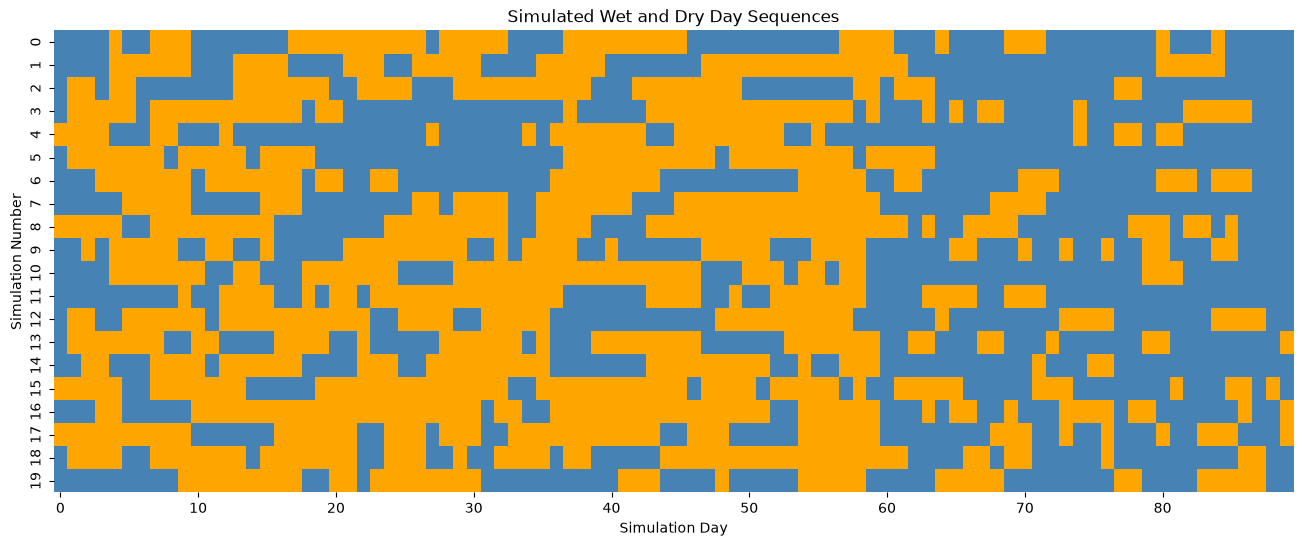

In [66]:
from matplotlib.colors import ListedColormap

rainfall_cmap = ListedColormap([
    "steelblue",
    "orange"
])

plt.figure(figsize=(16, 6))

sns.heatmap(
    simulations[:20],
    cmap=rainfall_cmap,
    vmin=0,
    vmax=1,
    cbar=False,
    xticklabels=10,
    yticklabels=True
)

plt.title("Simulated Wet and Dry Day Sequences")
plt.xlabel("Simulation Day")
plt.ylabel("Simulation Number")
plt.show()

In [67]:
def extract_dry_spell_lengths(sequence):

    lengths = []
    streak = 0

    for state in sequence:

        if state == 1:
            streak += 1

        else:
            if streak > 0:
                lengths.append(streak)

            streak = 0

    if streak > 0:
        lengths.append(streak)

    return lengths

In [68]:
example_sequence = [
    0, 1, 1, 1, 0,
    1, 1, 0, 1
]

extract_dry_spell_lengths(example_sequence)

[3, 2, 1]

In [69]:
assert extract_dry_spell_lengths(
    [0, 0, 0]
) == []

assert extract_dry_spell_lengths(
    [1, 1, 1]
) == [3]

assert extract_dry_spell_lengths(
    [1, 0, 1]
) == [1, 1]

print("All dry spell extraction tests passed.")

All dry spell extraction tests passed.


In [70]:
def analyse_simulations(simulations):

    results = []

    for simulation in simulations:

        spells = extract_dry_spell_lengths(
            simulation
        )

        results.append({
            "total_dry_days": int(
                simulation.sum()
            ),

            "number_of_dry_spells": len(spells),

            "longest_dry_spell": max(
                spells, default=0
            ),

            "average_dry_spell": (
                np.mean(spells)
                if spells else np.nan
            ),

            "has_7_day_spell": any(
                length >= 7
                for length in spells
            ),

            "has_14_day_spell": any(
                length >= 14
                for length in spells
            ),

            "has_21_day_spell": any(
                length >= 21
                for length in spells
            )
        })

    return pd.DataFrame(results)

In [71]:
simulation_results = analyse_simulations(
    simulations
)

simulation_results.head(10)

,total_dry_days,number_of_dry_spells,longest_dry_spell,average_dry_spell,has_7_day_spell,has_14_day_spell,has_21_day_spell
0,38,10,10,3.800000,True,False,False
1,43,7,15,6.142857,True,True,False
2,40,9,10,4.444444,True,False,False
3,45,11,15,4.090909,True,True,False
4,30,11,8,2.727273,True,False,False
5,41,6,11,6.833333,True,False,False
6,42,10,8,4.200000,True,False,False
7,40,7,15,5.714286,True,True,False
8,57,10,19,5.700000,True,True,False
9,42,16,9,2.625000,True,False,False


In [72]:
probability_7_days = (
    simulation_results["has_7_day_spell"].mean()
)

probability_14_days = (
    simulation_results["has_14_day_spell"].mean()
)

probability_21_days = (
    simulation_results["has_21_day_spell"].mean()
)

print(
    f"Probability of a 7+ day dry spell: "
    f"{probability_7_days:.2%}"
)

print(
    f"Probability of a 14+ day dry spell: "
    f"{probability_14_days:.2%}"
)

print(
    f"Probability of a 21+ day dry spell: "
    f"{probability_21_days:.2%}"
)

Probability of a 7+ day dry spell: 97.12%
Probability of a 14+ day dry spell: 44.60%
Probability of a 21+ day dry spell: 11.41%


In [73]:
from scipy.stats import norm

def wilson_interval(successes, n, confidence=0.95):
    if n <= 0 or not 0 <= successes <= n:
        raise ValueError('Invalid binomial counts')
    p = successes / n
    z = norm.ppf((1 + confidence) / 2)
    d = 1 + z*z/n
    center = (p + z*z/(2*n))/d
    half = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))/d
    return max(0., center-half), min(1., center+half)

def risk_intervals(results, scenario):
    rows = []
    for k in (7,14,21):
        successes = int(results[f'has_{k}_day_spell'].sum())
        n = len(results)
        lo, hi = wilson_interval(successes,n)
        rows.append(dict(scenario=scenario, threshold_days=k, simulations=n, successes=successes, probability=successes/n, ci_lower=lo, ci_upper=hi))
    return pd.DataFrame(rows)

assert wilson_interval(0,100)[1] > 0
assert wilson_interval(100,100)[0] < 1
risk_tables = [risk_intervals(simulation_results, '90-day scenario')]
from scipy.stats import t
mean_rows = []
for metric in ['total_dry_days','number_of_dry_spells','longest_dry_spell','average_dry_spell']:
    values = simulation_results[metric].dropna()
    half = t.ppf(.975,len(values)-1)*values.std(ddof=1)/np.sqrt(len(values))
    mean_rows.append(dict(metric=metric, n=len(values), mean=values.mean(), mean_ci_lower=values.mean()-half, mean_ci_upper=values.mean()+half, prediction_lower=values.quantile(.025), prediction_upper=values.quantile(.975)))
mean_intervals = pd.DataFrame(mean_rows)
display(risk_tables[0], mean_intervals)
mean_intervals.to_csv(RESULTS / 'monte_carlo_mean_intervals.csv', index=False)

,scenario,threshold_days,simulations,successes,probability,ci_lower,ci_upper
0,90-day scenario,7,10000,9712,0.9712,0.967737,0.974301
1,90-day scenario,14,10000,4460,0.4460,0.436280,0.455761
2,90-day scenario,21,10000,1141,0.1141,0.108016,0.120480


,metric,n,mean,mean_ci_lower,mean_ci_upper,prediction_lower,prediction_upper
0,total_dry_days,10000,47.184900,47.029430,47.340370,31.000000,62.0
1,number_of_dry_spells,10000,10.384300,10.343216,10.425384,6.000000,15.0
2,longest_dry_spell,10000,13.875400,13.768706,13.982094,6.000000,28.0
3,average_dry_spell,10000,4.754269,4.727070,4.781468,2.727273,8.0


In [74]:
print(
    "Expected total dry days:",
    simulation_results["total_dry_days"].mean()
)

print(
    "Expected longest dry spell:",
    simulation_results["longest_dry_spell"].mean()
)

print(
    "Expected number of dry spells:",
    simulation_results["number_of_dry_spells"].mean()
)

simulation_results.describe()

Expected total dry days: 47.1849
Expected longest dry spell: 13.8754
Expected number of dry spells: 10.3843


,total_dry_days,number_of_dry_spells,longest_dry_spell,average_dry_spell
count,10000.000000,10000.000000,10000.000000,10000.000000
mean,47.184900,10.384300,13.875400,4.754269
std,7.931343,2.095913,5.442999,1.387566
min,16.000000,4.000000,3.000000,1.600000
25%,42.000000,9.000000,10.000000,3.777778
50%,47.000000,10.000000,13.000000,4.545455
75%,53.000000,12.000000,17.000000,5.446970
max,75.000000,19.000000,51.000000,14.250000


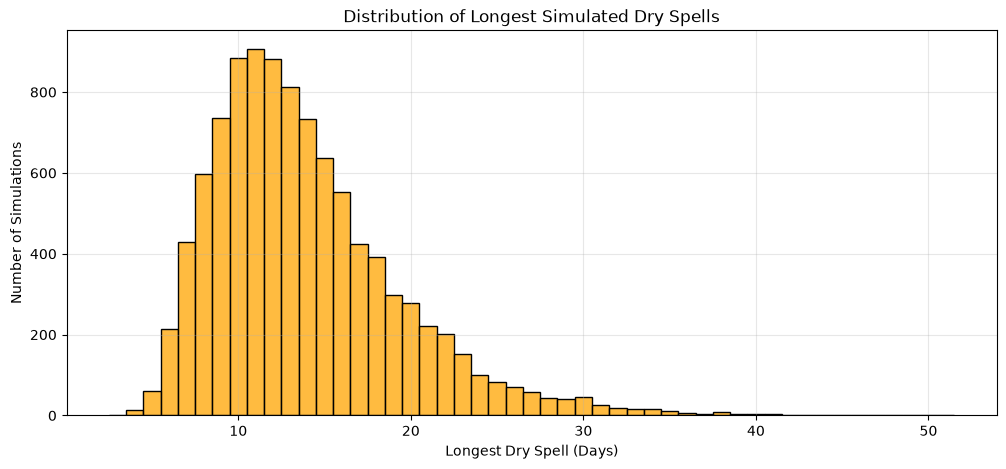

In [75]:
plt.figure(figsize=(12, 5))

sns.histplot(
    simulation_results["longest_dry_spell"],
    discrete=True,
    color="orange"
)

plt.title("Distribution of Longest Simulated Dry Spells")
plt.xlabel("Longest Dry Spell (Days)")
plt.ylabel("Number of Simulations")
plt.grid(alpha=0.3)
plt.show()

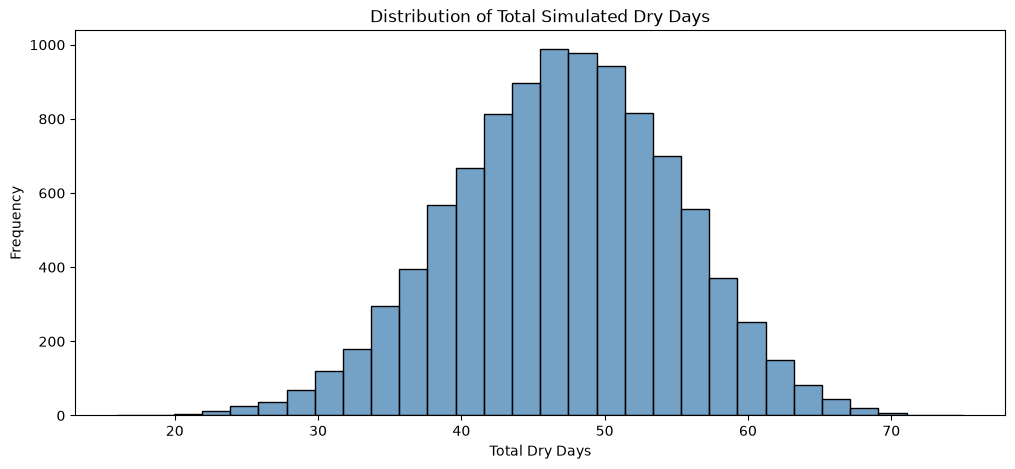

In [76]:
plt.figure(figsize=(12, 5))

sns.histplot(
    simulation_results["total_dry_days"],
    bins=30,
    color="steelblue"
)

plt.title("Distribution of Total Simulated Dry Days")
plt.xlabel("Total Dry Days")
plt.ylabel("Frequency")
plt.show()

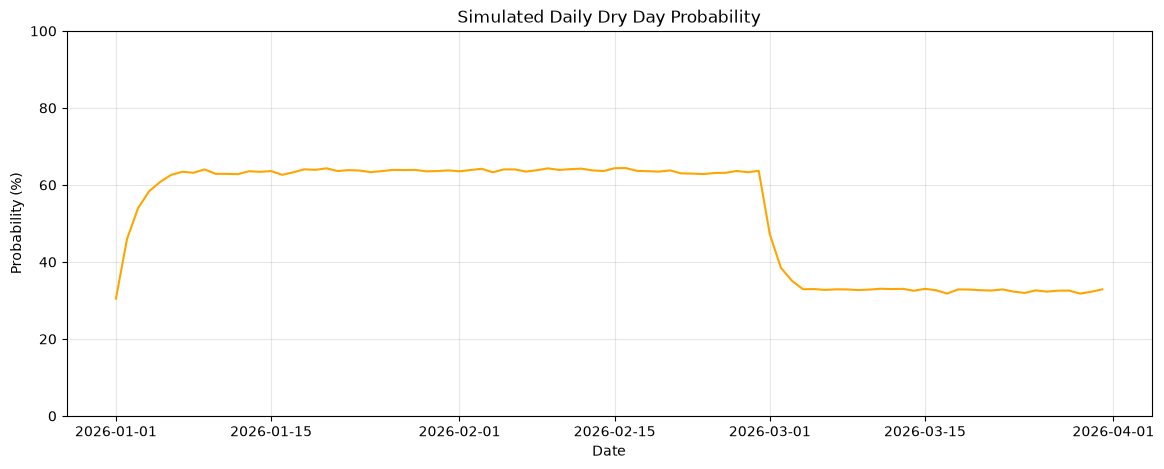

In [77]:
daily_dry_probability = simulations.mean(axis=0)

plt.figure(figsize=(14, 5))

plt.plot(
    simulation_dates,
    daily_dry_probability * 100,
    color="orange"
)

plt.title("Simulated Daily Dry Day Probability")
plt.xlabel("Date")
plt.ylabel("Probability (%)")
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.show()

In [78]:
season_start_dates = {
    "Northeast Monsoon": "2026-01-01",
    "First Inter-monsoon": "2026-03-01",
    "Southwest Monsoon": "2026-05-01",
    "Second Inter-monsoon": "2026-10-01"
}

seasonal_results = []

for season, start_date in season_start_dates.items():

    dates, simulated_data = simulate_rainfall(
        start_date=start_date,
        num_days=60,
        num_simulations=10000,
        initial_state=0,
        seed=42
    )

    results = analyse_simulations(
        simulated_data
    )

    risk_tables.append(risk_intervals(results, season))

    seasonal_results.append({
        "season": season,

        "expected_dry_days":
            results["total_dry_days"].mean(),

        "expected_longest_spell":
            results["longest_dry_spell"].mean(),

        "probability_7_days":
            results["has_7_day_spell"].mean(),

        "probability_14_days":
            results["has_14_day_spell"].mean(),

        "probability_21_days":
            results["has_21_day_spell"].mean()
    })

seasonal_summary = pd.DataFrame(
    seasonal_results
)

display(seasonal_summary)
all_risk_intervals = pd.concat(risk_tables, ignore_index=True)
all_risk_intervals.to_csv(RESULTS / "monte_carlo_risk_intervals.csv", index=False)
display(all_risk_intervals)

,season,expected_dry_days,expected_longest_spell,probability_7_days,probability_14_days,probability_21_days
0,Northeast Monsoon,37.3111,13.5841,0.9601,0.4268,0.1081
1,First Inter-monsoon,19.3325,6.2618,0.3863,0.0172,0.0007
2,Southwest Monsoon,3.3076,1.8605,0.0054,0.0000,0.0000
3,Second Inter-monsoon,9.2897,4.1542,0.1346,0.0022,0.0000


,scenario,threshold_days,simulations,successes,probability,ci_lower,ci_upper
0,90-day scenario,7,10000,9712,0.9712,0.967737,0.974301
1,90-day scenario,14,10000,4460,0.4460,0.436280,0.455761
2,90-day scenario,21,10000,1141,0.1141,0.108016,0.120480
3,Northeast Monsoon,7,10000,9601,0.9601,0.956084,0.963763
4,Northeast Monsoon,14,10000,4268,0.4268,0.417136,0.436521
5,Northeast Monsoon,21,10000,1081,0.1081,0.102164,0.114337
6,First Inter-monsoon,7,10000,3863,0.3863,0.376802,0.395885
7,First Inter-monsoon,14,10000,172,0.0172,0.014831,0.019940
8,First Inter-monsoon,21,10000,7,0.0007,0.000339,0.001444
9,Southwest Monsoon,7,10000,54,0.0054,0.004141,0.007039


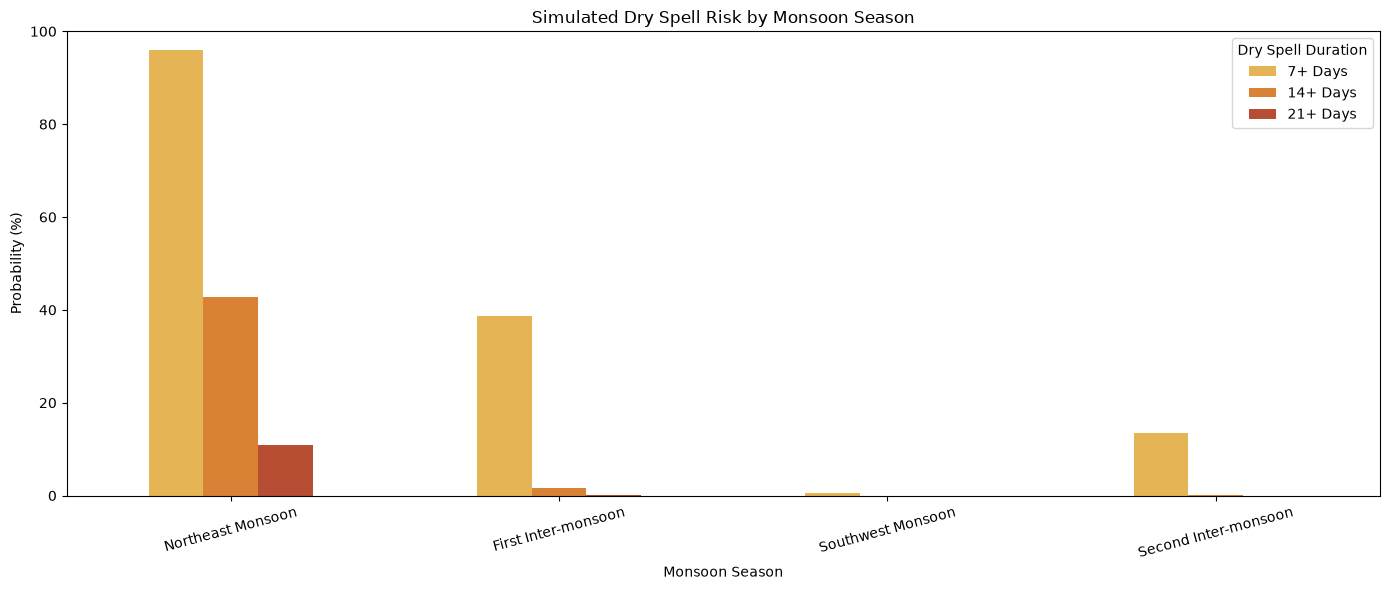

In [79]:
risk_columns = [
    "probability_7_days",
    "probability_14_days",
    "probability_21_days"
]

risk_data = (
    seasonal_summary
    .set_index("season")[risk_columns] * 100
)

risk_data.columns = [
    "7+ Days",
    "14+ Days",
    "21+ Days"
]

risk_data.plot(
    kind="bar",
    figsize=(14, 6),
    color=["#E5B454", "#D98236", "#B74D32"]
)

plt.title("Simulated Dry Spell Risk by Monsoon Season")
plt.ylabel("Probability (%)")
plt.xlabel("Monsoon Season")
plt.xticks(rotation=15)
plt.ylim(0, 100)
plt.legend(title="Dry Spell Duration")
plt.tight_layout()
plt.show()

In [80]:
from pathlib import Path

RESULTS.mkdir(exist_ok=True)

In [81]:
simulation_results.to_csv(
    RESULTS / "monte_carlo_results.csv",
    index=False
)

In [82]:
seasonal_summary.to_csv(
    RESULTS / "seasonal_simulation_summary.csv",
    index=False
)

## Observations

- A total of 10,000 rainfall scenarios were
  generated for each simulation experiment.

- The Northeast Monsoon simulation produced 37.31 expected dry days over 60 days and a 96.01% chance of a 7+ day dry spell.

- The Southwest Monsoon simulation produced 3.31 expected dry days over 60 days and a 0.54% chance of a 7+ day dry spell.

- The probability of experiencing a dry spell
  lasting at least seven days was 97.12% in the 90-day simulation.

- The seasonal comparison indicates that Northeast Monsoon had the highest 7+ day dry spell risk (96.01%), while Southwest Monsoon had the lowest (0.54%).

## Limitations

- The first-order Markov chain assumes that the
  next day's rainfall state depends on the
  previous day's state and the monsoon season.

- The model simulates rainfall occurrence rather
  than actual rainfall intensity.

- Historical transition probabilities may not
  fully represent future climate conditions.

- Dry spells crossing the simulation boundaries
  are measured only within the simulated period.

- Simulation results represent probabilistic
  scenarios rather than exact weather forecasts.

# 07 - Verification, Validation and Evaluation

## Objective

The objective of this section is to evaluate the
performance of the seasonal Markov chain and
Monte Carlo simulation using unseen historical
rainfall observations from 2019 to 2025.

The evaluation compares predicted probabilities,
simulated dry spell characteristics and actual
historical observations.

A seasonal climatological baseline is also used
to assess the effectiveness of the Markov model.

## Evaluation mathematics
The Brier score is $BS=n^{-1}\sum_t(p_t-X_t)^2$. The skill score is $BSS=1-BS_{model}/BS_{baseline}$. Positive skill indicates improvement over the training-only seasonal baseline. Daily predictions use the observed previous day; multi-day simulations instead propagate simulated states. The first test day is omitted from daily evaluation, but included in path validation.

In [83]:
evaluation_df = (
    test_df.copy()
    .sort_values("date")
    .reset_index(drop=True)
)

evaluation_df["previous_state"] = (
    evaluation_df["is_dry"].shift(1)
)

evaluation_df = evaluation_df.dropna(
    subset=["previous_state"]
).copy()

evaluation_df["previous_state"] = (
    evaluation_df["previous_state"].astype(int)
)

evaluation_df.head()

,date,rainfall_mm,year,month,is_dry,is_wet,season,day,day_of_year,consecutive_dry_days,spell_id,previous_state
1,2019-01-02,0.0,2019,1,1,0,Northeast Monsoon,2,2,6,1476,1
2,2019-01-03,0.0,2019,1,1,0,Northeast Monsoon,3,3,7,1476,1
3,2019-01-04,0.0,2019,1,1,0,Northeast Monsoon,4,4,8,1476,1
4,2019-01-05,0.0,2019,1,1,0,Northeast Monsoon,5,5,9,1476,1
5,2019-01-06,0.0,2019,1,1,0,Northeast Monsoon,6,6,10,1476,1


In [84]:
def predict_dry_probability(row):
    season = row["season"]

    previous_state = int(
        row["previous_state"]
    )

    matrix = model_matrices[season]

    return matrix[previous_state, 1]

In [85]:
evaluation_df["predicted_probability"] = (
    evaluation_df.apply(
        predict_dry_probability,
        axis=1
    )
)

evaluation_df[[
    "date",
    "season",
    "previous_state",
    "is_dry",
    "predicted_probability"
]].head(10)

,date,season,previous_state,is_dry,predicted_probability
1,2019-01-02,Northeast Monsoon,1,1,0.827091
2,2019-01-03,Northeast Monsoon,1,1,0.827091
3,2019-01-04,Northeast Monsoon,1,1,0.827091
4,2019-01-05,Northeast Monsoon,1,1,0.827091
5,2019-01-06,Northeast Monsoon,1,1,0.827091
6,2019-01-07,Northeast Monsoon,1,1,0.827091
7,2019-01-08,Northeast Monsoon,1,1,0.827091
8,2019-01-09,Northeast Monsoon,1,1,0.827091
9,2019-01-10,Northeast Monsoon,1,1,0.827091
10,2019-01-11,Northeast Monsoon,1,1,0.827091


In [86]:
from sklearn.metrics import brier_score_loss

markov_brier_score = brier_score_loss(
    evaluation_df["is_dry"],
    evaluation_df["predicted_probability"]
)

print(
    "Markov Model Brier Score:",
    round(markov_brier_score, 4)
)

Markov Model Brier Score: 0.1126


In [87]:
baseline_probabilities = (
    train_df.groupby("season")["is_dry"]
    .mean()
)

baseline_probabilities

season
First Inter-monsoon     0.332553
Northeast Monsoon       0.634349
Second Inter-monsoon    0.149883
Southwest Monsoon       0.056022
Name: is_dry, dtype: float64

In [88]:
evaluation_df["baseline_probability"] = (
    evaluation_df["season"].map(
        baseline_probabilities
    )
)

In [89]:
baseline_brier_score = brier_score_loss(
    evaluation_df["is_dry"],
    evaluation_df["baseline_probability"]
)

print(
    "Baseline Brier Score:",
    round(baseline_brier_score, 4)
)

print(
    "Markov Brier Score:",
    round(markov_brier_score, 4)
)

Baseline Brier Score: 0.1379
Markov Brier Score: 0.1126


In [90]:
brier_skill_score = (
    1 - markov_brier_score
    / baseline_brier_score
)

print(
    f"Brier Skill Score: "
    f"{brier_skill_score:.4f}"
)

print(
    f"Improvement over baseline: "
    f"{brier_skill_score:.2%}"
)

Brier Skill Score: 0.1835
Improvement over baseline: 18.35%


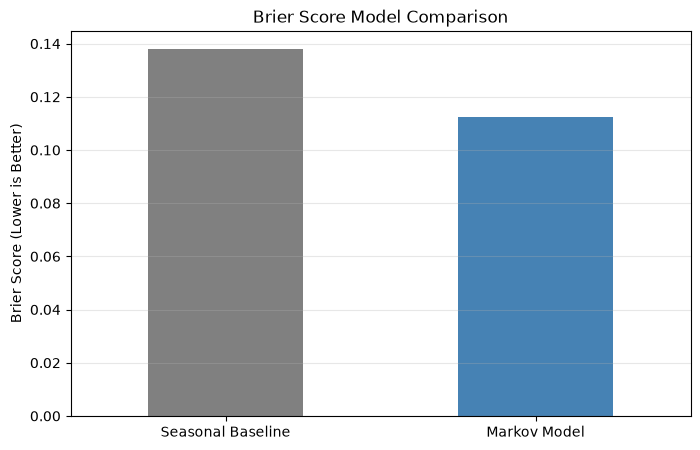

In [91]:
scores = pd.Series({
    "Seasonal Baseline": baseline_brier_score,
    "Markov Model": markov_brier_score
})

scores.plot(
    kind="bar",
    figsize=(8, 5),
    color=["gray", "steelblue"]
)

plt.title("Brier Score Model Comparison")
plt.ylabel("Brier Score (Lower is Better)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

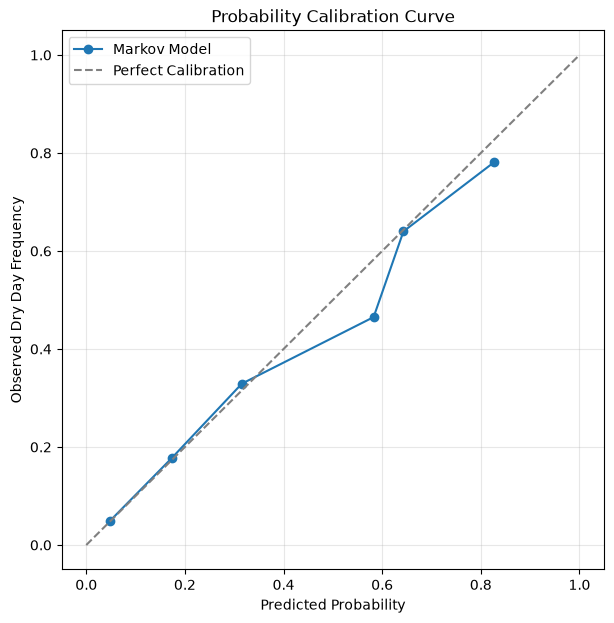

In [92]:
from sklearn.calibration import calibration_curve

observed_prob, predicted_prob = (
    calibration_curve(
        evaluation_df["is_dry"],
        evaluation_df["predicted_probability"],
        n_bins=10,
        strategy="uniform"
    )
)

plt.figure(figsize=(7, 7))

plt.plot(
    predicted_prob,
    observed_prob,
    marker="o",
    label="Markov Model"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect Calibration"
)

plt.xlabel("Predicted Probability")
plt.ylabel("Observed Dry Day Frequency")
plt.title("Probability Calibration Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [93]:
seasonal_evaluation = []

for season in seasons:

    subset = evaluation_df[
        evaluation_df["season"] == season
    ]

    model_score = brier_score_loss(
        subset["is_dry"],
        subset["predicted_probability"]
    )

    baseline_score = brier_score_loss(
        subset["is_dry"],
        subset["baseline_probability"]
    )

    skill_score = (
        1 - model_score / baseline_score
        if baseline_score > 0
        else np.nan
    )

    seasonal_evaluation.append({
        "season": season,
        "records": len(subset),
        "markov_brier_score": model_score,
        "baseline_brier_score": baseline_score,
        "brier_skill_score": skill_score
    })

seasonal_evaluation_df = pd.DataFrame(
    seasonal_evaluation
)

seasonal_evaluation_df

,season,records,markov_brier_score,baseline_brier_score,brier_skill_score
0,Northeast Monsoon,631,0.191892,0.242287,0.207996
1,First Inter-monsoon,427,0.175405,0.224314,0.218038
2,Southwest Monsoon,1071,0.052487,0.057858,0.092837
3,Second Inter-monsoon,427,0.083315,0.097900,0.148979


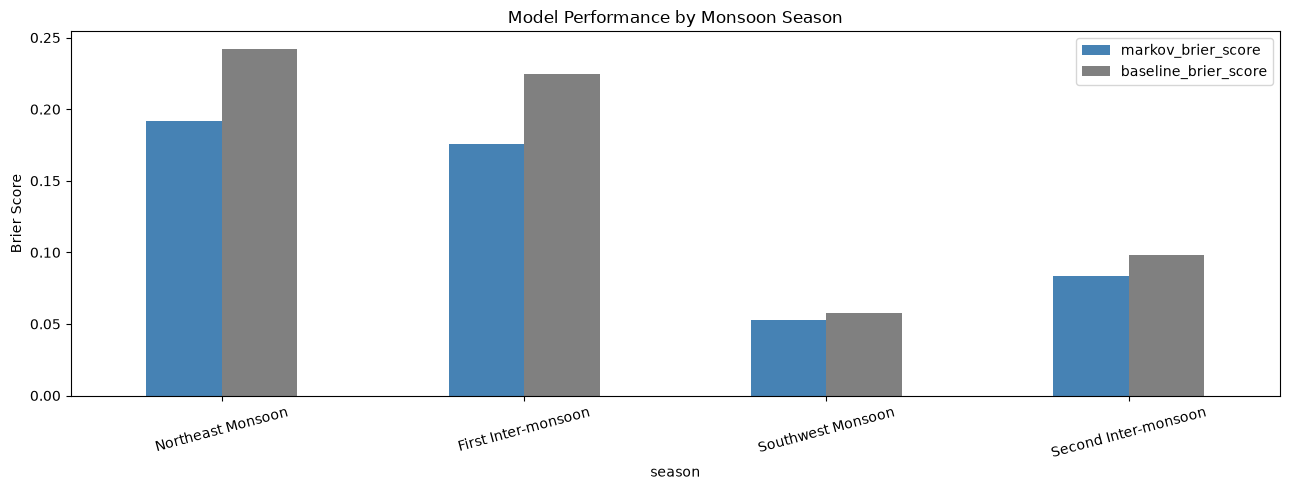

In [94]:
seasonal_evaluation_df.set_index(
    "season"
)[[
    "markov_brier_score",
    "baseline_brier_score"
]].plot(
    kind="bar",
    figsize=(13, 5),
    color=["steelblue", "gray"]
)

plt.title("Model Performance by Monsoon Season")
plt.ylabel("Brier Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [95]:
validation_start = test_df["date"].min()

validation_days = len(test_df)

initial_validation_state = int(
    train_df.sort_values("date")
    ["is_dry"].iloc[-1]
)

validation_dates, validation_simulations = (
    simulate_rainfall(
        start_date=validation_start,
        num_days=validation_days,
        num_simulations=1000,
        initial_state=initial_validation_state,
        seed=42
    )
)

print(validation_simulations.shape)

(1000, 2557)


In [96]:
actual_sequence = (
    test_df.sort_values("date")
    ["is_dry"].to_numpy()
)

actual_spells = extract_dry_spell_lengths(
    actual_sequence
)

actual_statistics = {
    "total_dry_days": int(
        actual_sequence.sum()
    ),

    "number_of_dry_spells": len(
        actual_spells
    ),

    "longest_dry_spell": max(
        actual_spells, default=0
    ),

    "average_dry_spell": (
        np.mean(actual_spells)
        if actual_spells else np.nan
    )
}

actual_statistics

{'total_dry_days': 634,
 'number_of_dry_spells': 202,
 'longest_dry_spell': 28,
 'average_dry_spell': np.float64(3.1386138613861387)}

In [97]:
validation_results = analyse_simulations(
    validation_simulations
)

validation_results.describe()

,total_dry_days,number_of_dry_spells,longest_dry_spell,average_dry_spell
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,665.768000,185.961000,24.624000,3.589572
std,32.519774,10.534156,6.070047,0.240358
min,563.000000,157.000000,12.000000,2.882353
25%,645.000000,179.000000,21.000000,3.419108
50%,665.000000,186.000000,24.000000,3.578219
75%,688.000000,193.000000,28.000000,3.749314
max,780.000000,221.000000,56.000000,4.453488


In [98]:
comparison_metrics = [
    "total_dry_days",
    "number_of_dry_spells",
    "longest_dry_spell",
    "average_dry_spell"
]

comparison_df = pd.DataFrame({
    "Actual": [
        actual_statistics[metric]
        for metric in comparison_metrics
    ],

    "Simulated Mean": [
        validation_results[metric].mean()
        for metric in comparison_metrics
    ],

    "Lower 2.5%": [
        validation_results[metric].quantile(0.025)
        for metric in comparison_metrics
    ],

    "Upper 97.5%": [
        validation_results[metric].quantile(0.975)
        for metric in comparison_metrics
    ]
}, index=comparison_metrics)

comparison_df.round(2)

,Actual,Simulated Mean,Lower 2.5%,Upper 97.5%
total_dry_days,634.00,665.77,601.95,730.02
number_of_dry_spells,202.00,185.96,166.00,208.00
longest_dry_spell,28.00,24.62,16.00,39.00
average_dry_spell,3.14,3.59,3.16,4.11


In [99]:
comparison_df["Within Simulated Range"] = (
    comparison_df["Actual"].between(
        comparison_df["Lower 2.5%"],
        comparison_df["Upper 97.5%"]
    )
)

comparison_df

,Actual,Simulated Mean,Lower 2.5%,Upper 97.5%,Within Simulated Range
total_dry_days,634.000000,665.768000,601.950000,730.025000,True
number_of_dry_spells,202.000000,185.961000,166.000000,208.000000,True
longest_dry_spell,28.000000,24.624000,16.000000,39.000000,True
average_dry_spell,3.138614,3.589572,3.164095,4.108587,False


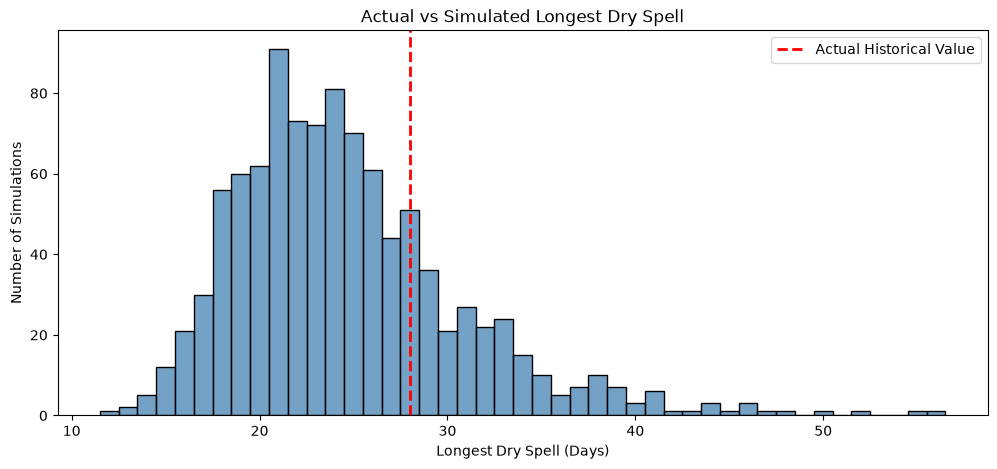

In [100]:
plt.figure(figsize=(12, 5))

sns.histplot(
    validation_results["longest_dry_spell"],
    discrete=True,
    color="steelblue"
)

plt.axvline(
    actual_statistics["longest_dry_spell"],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Actual Historical Value"
)

plt.title("Actual vs Simulated Longest Dry Spell")
plt.xlabel("Longest Dry Spell (Days)")
plt.ylabel("Number of Simulations")
plt.legend()
plt.show()

In [101]:
simulated_spell_lengths = []

for sequence in validation_simulations:
    simulated_spell_lengths.extend(
        extract_dry_spell_lengths(sequence)
    )

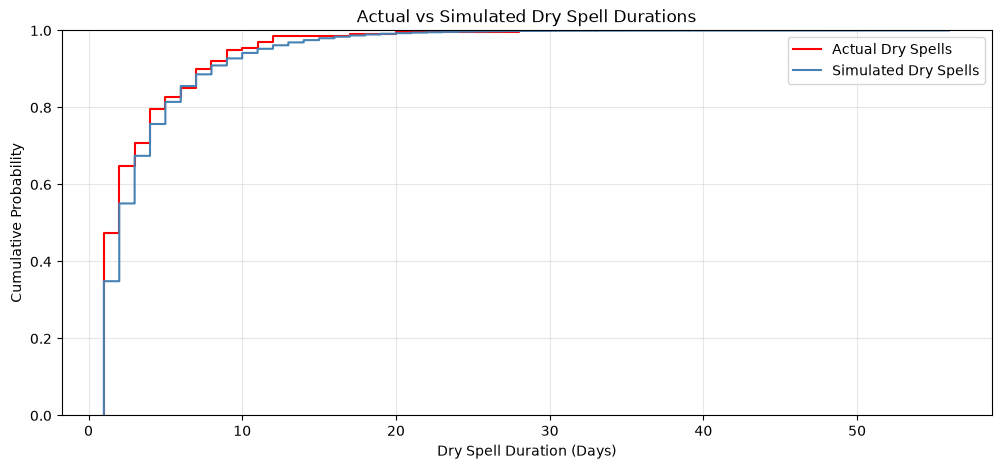

In [102]:
plt.figure(figsize=(12, 5))

sns.ecdfplot(
    actual_spells,
    label="Actual Dry Spells",
    color="red"
)

sns.ecdfplot(
    simulated_spell_lengths,
    label="Simulated Dry Spells",
    color="steelblue"
)

plt.title("Actual vs Simulated Dry Spell Durations")
plt.xlabel("Dry Spell Duration (Days)")
plt.ylabel("Cumulative Probability")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [103]:
validation_seasons = np.array([
    get_season(date.month)
    for date in validation_dates
])

seasonal_validation = []

for season in seasons:

    mask = validation_seasons == season

    actual_frequency = (
        actual_sequence[mask].mean()
    )

    simulated_frequencies = (
        validation_simulations[:, mask]
        .mean(axis=1)
    )

    seasonal_validation.append({
        "season": season,
        "actual_dry_frequency":
            actual_frequency,

        "simulated_dry_frequency":
            simulated_frequencies.mean(),

        "lower_95":
            np.quantile(
                simulated_frequencies, 0.025
            ),

        "upper_95":
            np.quantile(
                simulated_frequencies, 0.975
            )
    })

seasonal_validation_df = pd.DataFrame(
    seasonal_validation
)

seasonal_validation_df.round(4)

,season,actual_dry_frequency,simulated_dry_frequency,lower_95,upper_95
0,Northeast Monsoon,0.5965,0.6315,0.5617,0.6994
1,First Inter-monsoon,0.3396,0.3294,0.2529,0.4028
2,Southwest Monsoon,0.0616,0.0563,0.0383,0.0766
3,Second Inter-monsoon,0.1077,0.1538,0.0937,0.2201


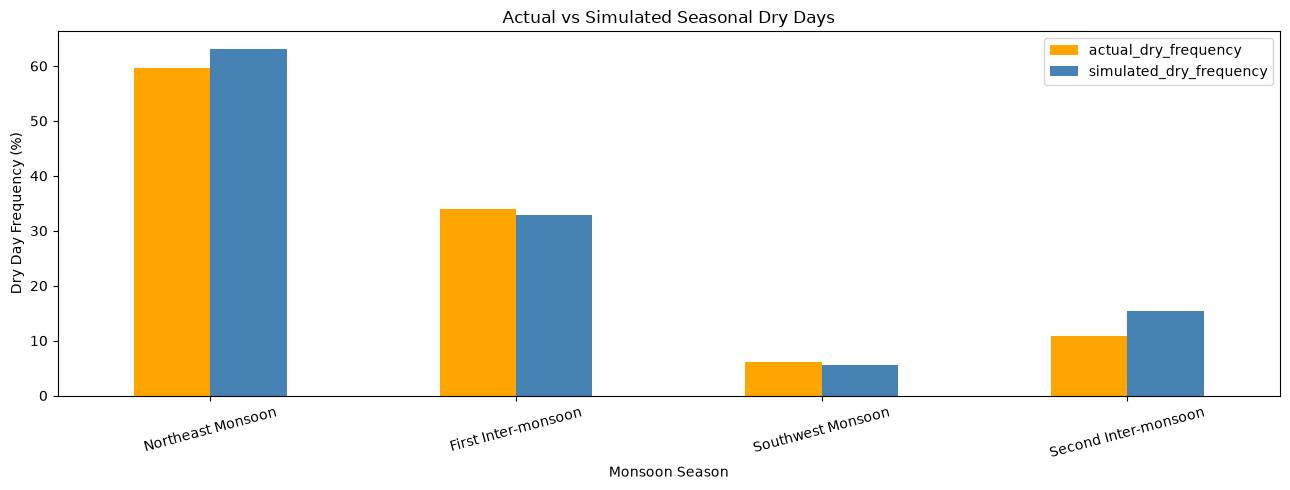

In [104]:
seasonal_validation_df.set_index(
    "season"
)[[
    "actual_dry_frequency",
    "simulated_dry_frequency"
]].mul(100).plot(
    kind="bar",
    figsize=(13, 5),
    color=["orange", "steelblue"]
)

plt.title("Actual vs Simulated Seasonal Dry Days")
plt.ylabel("Dry Day Frequency (%)")
plt.xlabel("Monsoon Season")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [105]:
from pathlib import Path

RESULTS.mkdir(exist_ok=True)

evaluation_df.to_csv(
    RESULTS / "daily_model_evaluation.csv",
    index=False
)

seasonal_evaluation_df.to_csv(
    RESULTS / "seasonal_model_evaluation.csv",
    index=False
)

comparison_df.to_csv(
    RESULTS / "simulation_validation.csv"
)

seasonal_validation_df.to_csv(
    RESULTS / "seasonal_simulation_validation.csv",
    index=False
)

In [106]:
evaluation_summary = {
    "testing_start": str(
        test_df["date"].min().date()
    ),

    "testing_end": str(
        test_df["date"].max().date()
    ),

    "markov_brier_score":
        float(markov_brier_score),

    "baseline_brier_score":
        float(baseline_brier_score),

    "brier_skill_score":
        float(brier_skill_score),

    "validation_simulations": 1000
}

with open(
    RESULTS / "evaluation_summary.json",
    "w"
) as file:

    json.dump(
        evaluation_summary,
        file,
        indent=4
    )

## Evaluation Findings

### Daily Probability Evaluation

The seasonal Markov chain achieved a Brier
score of 0.1126.

The seasonal climatological baseline achieved
a Brier score of 0.1379.

The Brier Skill Score was 0.1835 (18.35%).

This indicates that the Markov model performed better than the seasonal baseline on the testing data.

### Monte Carlo Simulation Validation

A total of 1,000 rainfall scenarios were
generated for the testing period.

The actual historical longest dry spell was
28 days, compared with a simulated mean
of 24.62 days.

The comparison of historical and simulated
dry spell statistics indicates that 3 of 4 measures were within their simulated 95% ranges; average dry spell length was outside its range.

### Seasonal Performance

The model performed best during First Inter-monsoon (Brier Skill Score 0.2180).

The model showed limitations during Southwest Monsoon (lowest Brier Skill Score 0.0928); the largest seasonal dry-day frequency gap was in Second Inter-monsoon (10.77% actual, 15.38% simulated).

### Limitations

- The first-order Markov chain considers only
  the previous day's rainfall state.

- The model does not incorporate temperature,
  humidity, atmospheric pressure or other
  meteorological variables.

- Historical probabilities may change due to
  climate variability and climate change.

- The simulator estimates probabilistic dry
  spell risks rather than exact future weather.

- Simulation intervals reflect variability
  under the fitted model and do not include
  all parameter uncertainty.

## Real-data grounding and training-only audit

### Data source and preparation

The recorded request used the [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api) with the ERA5 model, daily `precipitation_sum`, local `Asia/Colombo` dates and a requested point of **6.9355° N, 79.8487° E**. The saved CSV reports the selected grid-cell coordinates as **7.0° N, 80.0° E**. It is a model grid estimate, not a rain gauge at the requested point. The original retrieval date and exact CSV export action were not recorded. See [data provenance](../data/README.md) and [references](../REFERENCES.md).

After reading past the CSV metadata and renaming its columns, the source and cleaned daily values match exactly. The file has **12,784** consecutive dates from **1991-01-01 to 2025-12-31**, with no missing dates, duplicate dates, missing values or negative rainfall. The model calls a day **dry** if rainfall is below **1 mm**. The [Open-Meteo data licence](https://open-meteo.com/en/license) identifies API data as **CC BY 4.0**; [Copernicus terms](https://cds.climate.copernicus.eu/licences/licence-to-use-copernicus-products) also require attribution for ERA5 information. These data terms are separate from the project's MIT code licence.

### No test-data leakage into fitting

The code above splits the data **before** estimating probabilities: `train_df` contains **10,227** days from **1991-01-01 to 2018-12-31**, and `test_df` contains **2,557** days from **2019-01-01 to 2025-12-31**. The shifted next-day state and destination-day season are made **inside `train_df`**. Dropping its final row leaves **10,226 training transitions**; no 2019 transition enters the fit. Recalculating all four seasonal matrices from these counts matches every value in `models/seasonal_markov_model.json` exactly (maximum absolute difference **0**). The seasonal baseline is likewise computed only as `train_df.groupby("season")["is_dry"].mean()`. Earlier exploratory plots and summaries use the whole 1991–2025 series, so the test years were visible during exploration. This audit shows no test-data leakage into fitted probabilities or the baseline; it does not establish fully blind model selection.

The saved daily evaluation uses the fitted model and baseline **without updating them on test outcomes**. It uses the observed previous day's state as a one-day-ahead input; this is a conditional one-step evaluation, not a free-running forecast. The first test day has no previous state within `test_df`, so the **2,556** daily Brier-score records run from **2019-01-02 to 2025-12-31**. The `testing_start` value of **2019-01-01** in `evaluation_summary.json` names the overall holdout period; it is not the first scored daily record.

### Held-out findings and limits

On those 2,556 daily records, the Markov Brier score is **0.1125865**, versus **0.1378854** for the training-only seasonal baseline. The Brier Skill Score is **0.1834775** (about **18.35%** relative improvement). The saved [calibration graph](../figures/calibration.png) compares predicted bins with observed dry frequencies; it does not show perfect calibration. The seasonal Brier Skill Scores are **0.2080** (Northeast), **0.2180** (First Inter-monsoon), **0.0928** (Southwest) and **0.1490** (Second Inter-monsoon).

The separate **1,000-path** simulation check covers the whole 2019–2025 period. Three of four observed summary statistics fall inside the model's simulated 2.5%–97.5% ranges. **Average dry-spell length does not:** observed **3.139** days versus a simulated range of **3.164–4.109** days. The Second Inter-monsoon also shows a dry-frequency gap: **10.77%** observed versus **15.38%** simulated. These are real limitations of the fitted model. Reanalysis grid estimates, fixed seasonal probabilities and first-order memory further limit how far these findings can be applied.

## Independent exact probability and convergence

The fitted model still uses state **0 = wet** and **1 = dry** (rainfall below 1 mm). Let $q_t(i,r)$ be the probability that no spell of at least $k$ dry days has occurred in the first $t$ simulated days, that the latest state is $i$, and that the dry run **inside the simulation window** has length $r<k$. Start with $q_0(i_0,0)=1$, where $i_0$ is the state of the day before the window. It affects the first transition but is not counted as a simulated dry day.

For each destination day $t$, select its season $s(t)$ and transition matrix $P^{s(t)}$. From every surviving state, add wet mass to $q_t(0,0)$ and dry mass to $q_t(1,r+1)$ when $r+1<k$. When $r+1=k$, add that dry mass to an absorbing event total. Thus

$$p_{\mathrm{exact}}(L_{\max}\ge k)=1-\sum_{i=0}^{1}\sum_{r=0}^{k-1}q_T(i,r).$$

This dynamic program sums probabilities rather than drawing random paths. It is an independent check of the Monte Carlo engine, conditional on the same fitted transition matrices and seasonal calendar. The hand-check cases below test one and two days, the previous-day state, limiting wet/dry matrices, and a leap-year season boundary.

For $N$ simulated paths, the Monte Carlo estimate is $\hat p_N=N^{-1}\sum_{j=1}^{N}I(L_j\ge k)$. We compare it with the exact result using a stated tolerance of $3\sqrt{p_{\mathrm{exact}}(1-p_{\mathrm{exact}})/N}+1/N$ (three binomial standard errors plus one event-count step). This is a practical stochastic check, not a guarantee for every possible random seed.

Across $S$ seeds, the measured error is

$$\operatorname{RMSE}(N)=\sqrt{\frac{1}{S}\sum_{s=1}^{S}(\hat p_{N,s}-p_{\mathrm{exact}})^2}.$$

Independent-path Monte Carlo theory predicts $\sqrt{p_{\mathrm{exact}}(1-p_{\mathrm{exact}})/N}\propto N^{-1/2}$. The convergence experiment uses the existing 90-day, 7-day-spell, initially wet scenario, eight fixed seeds, and nested prefixes of 250 to 8,000 paths per seed. It does not change the original 10,000-path reference experiment.

In [107]:
def exact_dry_spell_probability(
    start_date, num_days, minimum_spell, initial_state=0, matrices=None
):
    if num_days < 1 or minimum_spell < 1 or initial_state not in (0, 1):
        raise ValueError("Days and spell length must be positive; state must be 0 or 1")
    if minimum_spell > num_days:
        return 0.0
    if matrices is None:
        matrices = model_matrices

    # Rows hold the previous wet/dry state; columns hold the within-window run.
    no_event = np.zeros((2, minimum_spell), dtype=float)
    no_event[initial_state, 0] = 1.0
    event_probability = 0.0

    for date in pd.date_range(start=start_date, periods=num_days, freq="D"):
        transition = np.asarray(matrices[get_season(date.month)], dtype=float)
        assert transition.shape == (2, 2)
        assert np.allclose(transition.sum(axis=1), 1.0)
        following = np.zeros_like(no_event)

        for previous_state in (0, 1):
            for run_length in range(minimum_spell):
                mass = no_event[previous_state, run_length]
                if mass == 0:
                    continue
                following[0, 0] += mass * transition[previous_state, 0]
                dry_mass = mass * transition[previous_state, 1]
                if run_length + 1 == minimum_spell:
                    event_probability += dry_mass
                else:
                    following[1, run_length + 1] += dry_mass

        no_event = following
        assert np.isclose(event_probability + no_event.sum(), 1.0, atol=1e-12, rtol=0)

    return float(event_probability)


In [108]:
example_matrix = np.array([[0.8, 0.2], [0.4, 0.6]])
example_matrices = {season: example_matrix for season in model_matrices}
boundary_matrices = dict(example_matrices)
boundary_matrices["First Inter-monsoon"] = np.array([[0.7, 0.3], [0.2, 0.8]])
always_wet = {season: np.array([[1.0, 0.0], [1.0, 0.0]]) for season in model_matrices}
always_dry = {season: np.array([[0.0, 1.0], [0.0, 1.0]]) for season in model_matrices}

hand_cases = [
    ("One day, previous wet", "2026-01-01", 1, 1, 0, example_matrices, 0.2),
    ("One day, previous dry", "2026-01-01", 1, 1, 1, example_matrices, 0.6),
    ("Two dry days: 0.2 x 0.6", "2026-01-01", 2, 2, 0, example_matrices, 0.12),
    ("Leap day to March: 0.2 x 0.8", "2024-02-29", 2, 2, 0, boundary_matrices, 0.16),
    ("Always wet", "2026-01-01", 5, 2, 0, always_wet, 0.0),
    ("Always dry, spell equals window", "2026-01-01", 5, 5, 0, always_dry, 1.0),
    ("Spell longer than window", "2026-01-01", 4, 5, 1, always_dry, 0.0),
]
hand_rows = []
for name, start, days, spell, initial, matrices, expected in hand_cases:
    calculated = exact_dry_spell_probability(start, days, spell, initial, matrices)
    passed = bool(np.isclose(calculated, expected, atol=1e-12, rtol=0))
    hand_rows.append({"case": name, "expected": expected, "exact_dp": calculated, "pass": passed})
hand_checks = pd.DataFrame(hand_rows)
display(hand_checks)
assert hand_checks["pass"].all(), "A hand-calculable exact case failed"
print("Independent exact hand checks: PASS")


,case,expected,exact_dp,pass
0,"One day, previous wet",0.20,0.20,True
1,"One day, previous dry",0.60,0.60,True
2,Two dry days: 0.2 x 0.6,0.12,0.12,True
3,Leap day to March: 0.2 x 0.8,0.16,0.16,True
4,Always wet,0.00,0.00,True
5,"Always dry, spell equals window",1.00,1.00,True
6,Spell longer than window,0.00,0.00,True


Independent exact hand checks: PASS


In [109]:
scenario_windows = {"90-day scenario": ("2026-01-01", 90)}
scenario_windows.update({season: (start, 60) for season, start in season_start_dates.items()})

exact_rows = []
for row in all_risk_intervals.itertuples(index=False):
    start, days = scenario_windows[row.scenario]
    exact = exact_dry_spell_probability(start, days, int(row.threshold_days), 0)
    standard_error = np.sqrt(exact * (1 - exact) / int(row.simulations))
    tolerance = 3 * standard_error + 1 / int(row.simulations)
    error = abs(float(row.probability) - exact)
    exact_rows.append({
        "scenario": row.scenario,
        "threshold_days": int(row.threshold_days),
        "simulations": int(row.simulations),
        "exact_probability": exact,
        "monte_carlo_probability": float(row.probability),
        "absolute_error": error,
        "tolerance": tolerance,
        "pass": bool(error <= tolerance + 1e-15),
    })

exact_comparison = pd.DataFrame(exact_rows)
display(exact_comparison)
assert len(exact_comparison) == 15
assert exact_comparison["pass"].all(), "Monte Carlo disagrees with the exact check"
exact_comparison.to_csv(RESULTS / "exact_vs_monte_carlo.csv", index=False)
exact_reference_probability = exact_comparison.iloc[0]["exact_probability"]
print(f"Exact 90-day, 7+ day risk: {exact_reference_probability:.6%}")
print(f"Monte Carlo 90-day, 7+ day risk: {probability_7_days:.6%}")
print("Exact versus Monte Carlo checks: 15/15 PASS")


,scenario,threshold_days,simulations,exact_probability,monte_carlo_probability,absolute_error,tolerance,pass
0,90-day scenario,7,10000,9.704213e-01,0.9712,7.787434e-04,0.005183,True
1,90-day scenario,14,10000,4.384555e-01,0.4460,7.544476e-03,0.014986,True
2,90-day scenario,21,10000,1.122120e-01,0.1141,1.887963e-03,0.009569,True
3,Northeast Monsoon,7,10000,9.591329e-01,0.9601,9.671229e-04,0.006039,True
4,Northeast Monsoon,14,10000,4.188015e-01,0.4268,7.998476e-03,0.014901,True
5,Northeast Monsoon,21,10000,1.058238e-01,0.1081,2.276181e-03,0.009328,True
6,First Inter-monsoon,7,10000,3.840448e-01,0.3863,2.255175e-03,0.014691,True
7,First Inter-monsoon,14,10000,1.788550e-02,0.0172,6.854986e-04,0.004076,True
8,First Inter-monsoon,21,10000,6.976580e-04,0.0007,2.341983e-06,0.000892,True
9,Southwest Monsoon,7,10000,5.005464e-03,0.0054,3.945356e-04,0.002217,True


Exact 90-day, 7+ day risk: 97.042126%
Monte Carlo 90-day, 7+ day risk: 97.120000%
Exact versus Monte Carlo checks: 15/15 PASS


In [110]:
convergence_counts = np.array([250, 500, 1000, 2000, 4000, 8000])
convergence_seeds = [101, 211, 307, 401, 503, 601, 701, 809]
estimates_by_seed = []

for seed in convergence_seeds:
    _, paths = simulate_rainfall(
        start_date="2026-01-01",
        num_days=90,
        num_simulations=int(convergence_counts[-1]),
        initial_state=0,
        seed=seed,
    )
    events = analyse_simulations(paths)["has_7_day_spell"].to_numpy(dtype=int)
    cumulative_events = np.cumsum(events)
    estimates_by_seed.append(cumulative_events[convergence_counts - 1] / convergence_counts)

estimates_by_seed = np.asarray(estimates_by_seed)
measured_rmse = np.sqrt(
    np.mean((estimates_by_seed - exact_reference_probability) ** 2, axis=0)
)
theoretical_rmse = np.sqrt(
    exact_reference_probability * (1 - exact_reference_probability) / convergence_counts
)
measured_slope = float(np.polyfit(np.log(convergence_counts), np.log(measured_rmse), 1)[0])

convergence_table = pd.DataFrame({
    "simulations": convergence_counts,
    "seeds": len(convergence_seeds),
    "measured_rmse": measured_rmse,
    "theoretical_rmse": theoretical_rmse,
    "measured_to_theory": measured_rmse / theoretical_rmse,
})
assert np.isfinite(convergence_table[["measured_rmse", "theoretical_rmse"]]).all().all()
assert (convergence_table[["measured_rmse", "theoretical_rmse"]] > 0).all().all()
display(convergence_table)
convergence_table.to_csv(RESULTS / "monte_carlo_convergence.csv", index=False)
print("Convergence seeds:", convergence_seeds)
print(f"Measured log-log RMSE slope: {measured_slope:.3f}; theoretical slope: -0.500")


,simulations,seeds,measured_rmse,theoretical_rmse,measured_to_theory
0,250,8,0.008631,0.010715,0.805482
1,500,8,0.005821,0.007577,0.768314
2,1000,8,0.004172,0.005358,0.778756
3,2000,8,0.003644,0.003788,0.961942
4,4000,8,0.002969,0.002679,1.108196
5,8000,8,0.001953,0.001894,1.031177


Convergence seeds: [101, 211, 307, 401, 503, 601, 701, 809]
Measured log-log RMSE slope: -0.395; theoretical slope: -0.500


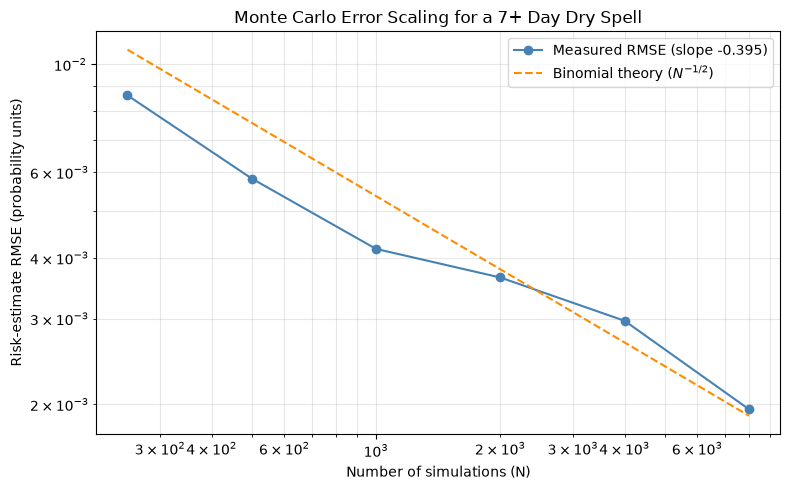

In [111]:
FIGURES = ROOT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(8, 5))
plt.loglog(
    convergence_counts, measured_rmse, "o-", color="steelblue",
    label=f"Measured RMSE (slope {measured_slope:.3f})",
)
plt.loglog(
    convergence_counts, theoretical_rmse, "--", color="darkorange",
    label=r"Binomial theory ($N^{-1/2}$)",
)
plt.xlabel("Number of simulations (N)")
plt.ylabel("Risk-estimate RMSE (probability units)")
plt.title("Monte Carlo Error Scaling for a 7+ Day Dry Spell")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES / "monte_carlo_convergence.png", dpi=160)
plt.show()


## Exact-probability observations and interpretation

Across eight fixed seeds, measured RMSE fell from **0.008631** at **250** simulations to **0.001953** at **8,000** simulations. The fitted log–log slope is **-0.395**, compared with the theoretical **−0.500**. The measured curve can fluctuate because it uses a finite number of seeds. The exact dynamic-programming probability checks the sampling algorithm under the fitted Markov model; it does not establish that the model predicts future rainfall perfectly.

## Controlled dry-spell risk sensitivity

Each sweep changes **one input at a time**. Within a sweep, the model matrices, 10,000 simulations per setting, and seed 42 stay fixed. All events mean at least one dry spell **inside** the simulated window. The previous-day state changes the first transition but does not count as a day in that window.

| Sweep | Changed input | Settings held fixed |
|---|---|---|
| Horizon | 30, 60, 90, 120 days | 1 Jan 2026; 7-day spell; previous day wet |
| Starting season | Jan, Mar, May, Oct start | 60 days; 7-day spell; previous day wet |
| Spell duration | 7, 14, 21 consecutive days | 1 Jan 2026; 90 days; previous day wet |
| Initial state | Previous day wet or dry | 1 Jan 2026; 90 days; 7-day spell |

The seasonal and spell-duration sweeps reuse the original simulation results. The 60-day horizon result reuses the January seasonal run, and the 90-day horizon and wet-initial-state results reuse the original reference run. New random paths are generated only for the missing horizon and dry-initial-state settings.

For each setting, $x$ out of $N$ paths contain the event and $\hat p=x/N$. The existing `wilson_interval(x, N, confidence=0.95)` gives a 95% interval for **Monte Carlo sampling uncertainty conditional on the fitted model**. Shared seeds make comparisons reproducible. These intervals do not include uncertainty in the historical transition estimates or future climate.

In [112]:
def sensitivity_record(parameter, setting, start_date, horizon_days, minimum_spell_days,
                       initial_state, successes):
    n = 10000
    successes = int(successes)
    lower, upper = wilson_interval(successes, n, confidence=0.95)
    return {
        "parameter": parameter,
        "setting": setting,
        "start_date": start_date,
        "horizon_days": horizon_days,
        "minimum_spell_days": minimum_spell_days,
        "initial_state": "Wet" if initial_state == 0 else "Dry",
        "simulations": n,
        "seed": 42,
        "successes": successes,
        "probability": successes / n,
        "ci_lower": lower,
        "ci_upper": upper,
    }


def existing_risk(scenario, threshold):
    matches = all_risk_intervals.loc[
        (all_risk_intervals["scenario"] == scenario)
        & (all_risk_intervals["threshold_days"] == threshold)
    ]
    assert len(matches) == 1
    row = matches.iloc[0]
    assert int(row["simulations"]) == 10000
    return int(row["successes"])


def show_sensitivity(table):
    visible = table[["setting", "successes", "probability", "ci_lower", "ci_upper"]].copy()
    for name in ("probability", "ci_lower", "ci_upper"):
        visible[name] = (100 * visible[name]).round(2)
    visible = visible.rename(columns={
        "probability": "risk (%)", "ci_lower": "95% lower (%)",
        "ci_upper": "95% upper (%)",
    })
    display(visible)


In [113]:
# One 120-day seeded run supplies the new 30-day and 120-day settings.
_, horizon_paths = simulate_rainfall("2026-01-01", 120, 10000, 0, 42)
assert np.array_equal(horizon_paths[:, :90], simulations)

horizon_rows = []
for days in (30, 60, 90, 120):
    if days == 60:
        successes = existing_risk("Northeast Monsoon", 7)
    elif days == 90:
        successes = existing_risk("90-day scenario", 7)
    else:
        successes = int(analyse_simulations(horizon_paths[:, :days])["has_7_day_spell"].sum())
    horizon_rows.append(sensitivity_record(
        "Horizon", f"{days} days", "2026-01-01", days, 7, 0, successes
    ))

horizon_sensitivity = pd.DataFrame(horizon_rows)
assert int(analyse_simulations(horizon_paths[:, :60])["has_7_day_spell"].sum()) == existing_risk("Northeast Monsoon", 7)
assert horizon_sensitivity["successes"].is_monotonic_increasing
show_sensitivity(horizon_sensitivity)


,setting,successes,risk (%),95% lower (%),95% upper (%)
0,30 days,7683,76.83,75.99,77.65
1,60 days,9601,96.01,95.61,96.38
2,90 days,9712,97.12,96.77,97.43
3,120 days,9788,97.88,97.58,98.14


In [114]:
season_rows = []
for season, start in season_start_dates.items():
    season_rows.append(sensitivity_record(
        "Starting season", season, start, 60, 7, 0, existing_risk(season, 7)
    ))
season_sensitivity = pd.DataFrame(season_rows)
show_sensitivity(season_sensitivity)


,setting,successes,risk (%),95% lower (%),95% upper (%)
0,Northeast Monsoon,9601,96.01,95.61,96.38
1,First Inter-monsoon,3863,38.63,37.68,39.59
2,Southwest Monsoon,54,0.54,0.41,0.70
3,Second Inter-monsoon,1346,13.46,12.81,14.14


In [115]:
spell_rows = []
for minimum_days in (7, 14, 21):
    spell_rows.append(sensitivity_record(
        "Minimum spell duration", f"{minimum_days}+ days", "2026-01-01",
        90, minimum_days, 0, existing_risk("90-day scenario", minimum_days)
    ))
spell_sensitivity = pd.DataFrame(spell_rows)
assert spell_sensitivity["successes"].is_monotonic_decreasing
show_sensitivity(spell_sensitivity)


,setting,successes,risk (%),95% lower (%),95% upper (%)
0,7+ days,9712,97.12,96.77,97.43
1,14+ days,4460,44.60,43.63,45.58
2,21+ days,1141,11.41,10.80,12.05


In [116]:
_, dry_initial_paths = simulate_rainfall("2026-01-01", 90, 10000, 1, 42)
dry_initial_successes = int(
    analyse_simulations(dry_initial_paths)["has_7_day_spell"].sum()
)
state_sensitivity = pd.DataFrame([
    sensitivity_record("Previous-day state", "Wet", "2026-01-01", 90, 7, 0,
                       existing_risk("90-day scenario", 7)),
    sensitivity_record("Previous-day state", "Dry", "2026-01-01", 90, 7, 1,
                       dry_initial_successes),
])
show_sensitivity(state_sensitivity)


,setting,successes,risk (%),95% lower (%),95% upper (%)
0,Wet,9712,97.12,96.77,97.43
1,Dry,9746,97.46,97.13,97.75


In [117]:
sensitivity_tables = [horizon_sensitivity, season_sensitivity,
                      spell_sensitivity, state_sensitivity]
sensitivity_summary = pd.concat(sensitivity_tables, ignore_index=True)
assert len(sensitivity_summary) == 13
assert (sensitivity_summary["simulations"] == 10000).all()
assert (sensitivity_summary["seed"] == 42).all()
assert sensitivity_summary["successes"].between(0, 10000).all()
assert sensitivity_summary["probability"].between(
    sensitivity_summary["ci_lower"], sensitivity_summary["ci_upper"]
).all()
assert sensitivity_summary[["ci_lower", "ci_upper"]].ge(0).all().all()
assert sensitivity_summary[["ci_lower", "ci_upper"]].le(1).all().all()
assert sensitivity_summary.loc[
    (sensitivity_summary["parameter"] == "Horizon")
    & (sensitivity_summary["horizon_days"] == 90), "successes"
].iloc[0] == 9712

sensitivity_summary.to_csv(RESULTS / "sensitivity_analysis.csv", index=False)
print("X5 checks: PASS; 13 controlled settings; 95% Wilson intervals")


X5 checks: PASS; 13 controlled settings; 95% Wilson intervals


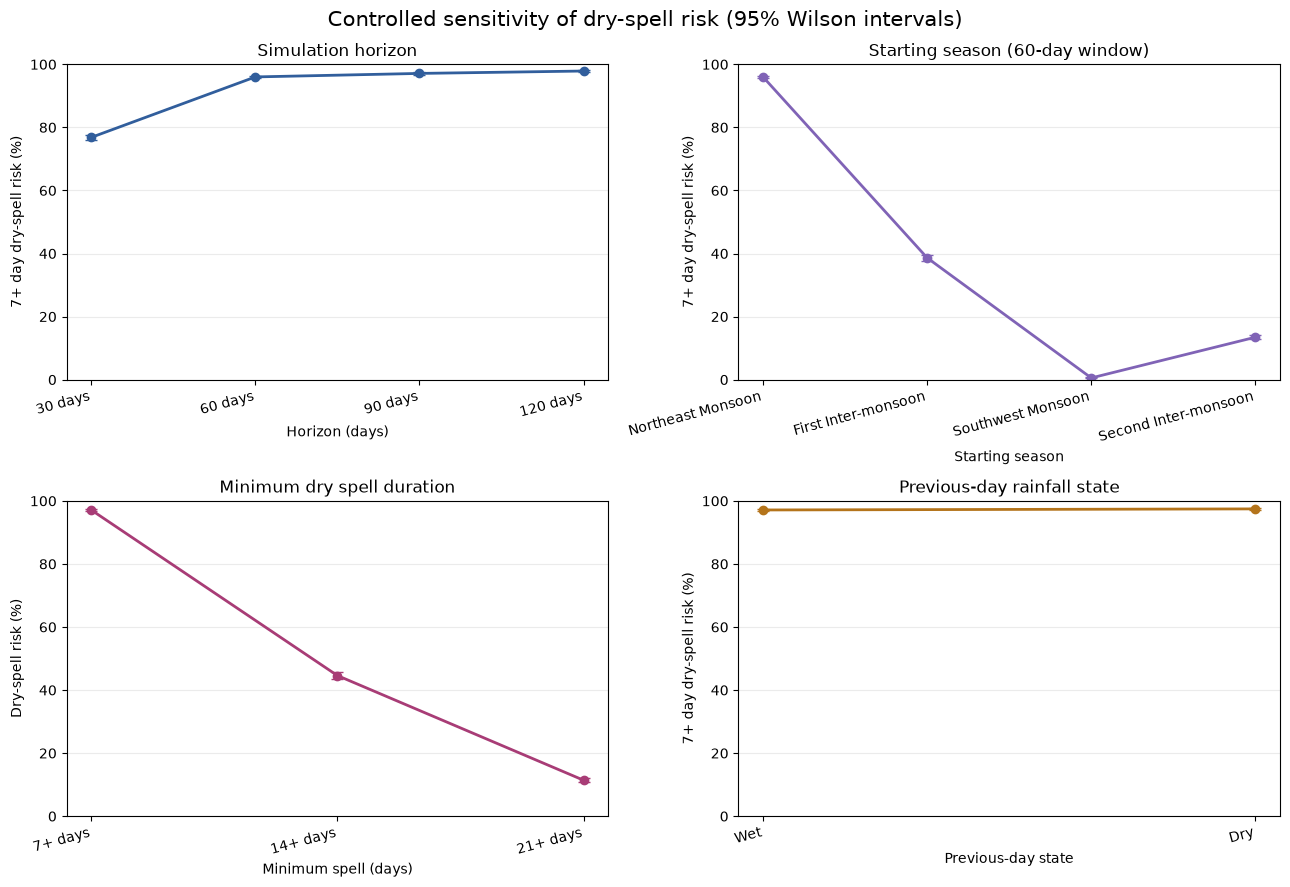

In [118]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
plot_groups = [
    (horizon_sensitivity, "Simulation horizon", "Horizon (days)", "#315E9C"),
    (season_sensitivity, "Starting season (60-day window)", "Starting season", "#8063B6"),
    (spell_sensitivity, "Minimum dry spell duration", "Minimum spell (days)", "#A83C76"),
    (state_sensitivity, "Previous-day rainfall state", "Previous-day state", "#B4741B"),
]

for ax, (table, title, x_label, color) in zip(axes.flat, plot_groups):
    x = np.arange(len(table))
    probability = 100 * table["probability"].to_numpy()
    lower = 100 * (table["probability"] - table["ci_lower"]).to_numpy()
    upper = 100 * (table["ci_upper"] - table["probability"]).to_numpy()
    ax.errorbar(x, probability, yerr=[lower, upper], fmt="o-", capsize=4,
                color=color, linewidth=2, markersize=6)
    ax.set_xticks(x, table["setting"], rotation=15, ha="right")
    ax.set_title(title)
    ax.set_xlabel(x_label)
    ax.set_ylabel("7+ day dry-spell risk (%)" if title != "Minimum dry spell duration"
                  else "Dry-spell risk (%)")
    ax.set_ylim(0, 100)
    ax.grid(axis="y", alpha=0.25)

fig.suptitle("Controlled sensitivity of dry-spell risk (95% Wilson intervals)", fontsize=15)
fig.tight_layout()
fig.savefig(ROOT / "figures" / "sensitivity_analysis.png", dpi=160,
            bbox_inches="tight")
plt.show()


## Sensitivity observations and interpretation

With the same January start, 7-day threshold, and initially wet state, risk rose from **76.83%** over 30 days to **97.88%** over 120 days. A longer window gives more chances for a qualifying spell.

With a fixed 60-day window, risk was **96.01%** for a January start, **38.63%** for March, **0.54%** for May, and **13.46%** for October. These are start-date experiments; the 60-day windows can cross a season boundary.

For the same 90-day January window, making the required spell longer reduced risk from **97.12%** (7+ days) to **44.60%** (14+ days) and **11.41%** (21+ days).

Changing only the previous day's state gave **97.12%** after a wet day and **97.46%** after a dry day, a difference of **0.34 percentage points** in this experiment. The previous day is not itself part of the counted dry spell.

The tables and plot show 95% Wilson intervals for each estimated probability. Those intervals describe finite-simulation sampling error under the fitted Markov model. Their overlap alone is not a formal test of differences, and they do not cover model uncertainty or a changing climate.

Within the selected settings, **starting season and minimum spell duration** changed the estimate most (ranges of 95.47 and 85.71 percentage points). **Horizon** also mattered (21.05 points from 30 to 120 days). The observed **previous-day state** difference was much smaller (0.34 points); its two Wilson intervals overlap, so this run alone does not show a clear difference. These ranges describe the tested settings, not a universal ranking of inputs.

# 08 - Discussion, Limitations and References

## Conclusion

For the 90-day reference scenario beginning on 1 January 2026, 10,000 seeded simulations estimated a **97.12%** chance of at least one dry spell lasting seven days. The seasonal 60-day experiments show a much higher seven-day risk in the Northeast Monsoon (**96.01%**) than in the Southwest Monsoon (**0.54%**). These are historical-risk scenarios, not operational weather forecasts.

On held-out daily data from 2019–2025, the Markov model's Brier score was **0.11259**, compared with **0.13789** for the training-only seasonal baseline. The Brier Skill Score was **0.18348**, indicating improvement over that baseline. In path validation, the observed average dry-spell length was **3.14 days**, just below the simulated 95% path range of **3.16–4.11 days**. This shows a limitation even though some other observed summaries fell within their simulated ranges.

The model uses only the previous wet/dry state and fixed seasonal transition probabilities. It models rainfall occurrence below or above **1 mm**, not rainfall amount. The confidence intervals describe Monte Carlo sampling uncertainty conditional on the fitted model; they do not include uncertainty in future climate or fitted parameters.

## Dataset and location

The historical daily precipitation series covers **1991-01-01 to 2025-12-31** in **mm per day**. It was requested from the [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api) using the **ERA5** reanalysis product, for **6.9355° N, 79.8487° E** near Colombo. The source CSV reports the returned grid cell at **7.0° N, 80.0° E**, elevation **4 m**, in the **Asia/Colombo** timezone. It is a grid-cell estimate, not a rain-gauge observation at the requested point. The original retrieval date was not recorded; see [data provenance](../data/README.md).

Open-Meteo API data are supplied under [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/), with attribution and change notices. [Copernicus product terms](https://cds.climate.copernicus.eu/licences/licence-to-use-copernicus-products) also apply to the underlying ERA5 information. Weather data by Open-Meteo.com using ERA5 from the Copernicus Climate Change Service / ECMWF. Contains modified Copernicus Climate Change Service information. Neither the European Commission nor ECMWF is responsible for any use that may be made of the information or data it contains. The project's MIT source-code licence does not relicense the dataset.

## References

1. C. W. Richardson, “Stochastic simulation of daily precipitation, temperature, and solar radiation,” *Water Resources Research*, 17(1), 182–190, 1981. [doi:10.1029/WR017i001p00182](https://doi.org/10.1029/WR017i001p00182).
2. H. Hersbach *et al.*, “The ERA5 global reanalysis,” *Quarterly Journal of the Royal Meteorological Society*, 146(730), 1999–2049, 2020. [doi:10.1002/qj.3803](https://doi.org/10.1002/qj.3803).
3. G. W. Brier, “Verification of forecasts expressed in terms of probability,” *Monthly Weather Review*, 78(1), 1–3, 1950. [DOI record](https://doi.org/10.1175/1520-0493%281950%29078%3C0001%3AVOFEIT%3E2.0.CO%3B2).
4. E. B. Wilson, “Probable inference, the law of succession, and statistical inference,” *Journal of the American Statistical Association*, 22(158), 209–212, 1927. [doi:10.1080/01621459.1927.10502953](https://doi.org/10.1080/01621459.1927.10502953).
5. D. S. Wilks, *Statistical Methods in the Atmospheric Sciences*, 4th ed., Elsevier, 2019. [Publisher record](https://shop.elsevier.com/books/statistical-methods-in-the-atmospheric-sciences/wilks/978-0-12-815823-4).
6. Open-Meteo, [Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api) and [data licence](https://open-meteo.com/en/license). The full source request and dataset credits are in [data/README.md](../data/README.md); the full bibliography is in [REFERENCES.md](../REFERENCES.md).


In [119]:
assert probability_7_days >= probability_14_days >= probability_21_days
assert len(all_risk_intervals) == 15
assert all_risk_intervals.probability.between(all_risk_intervals.ci_lower-1e-12, all_risk_intervals.ci_upper+1e-12).all()
assert np.isclose(
    probability_7_days,
    0.9712,
    atol=1e-12,
    rtol=0
), "Reference simulation result changed"

print("Reference simulation verification: PASS")
print(f'Run All completed in {time.perf_counter()-NOTEBOOK_START:.2f} seconds (including setup and any upload wait).')


Reference simulation verification: PASS
Run All completed in 21.82 seconds (including setup and any upload wait).
